# Data Mining on TTC Subway Delays

Academic project following the KDD process (Knowledge Discovery in Databases).

## Contents

0. [Context and research questions](#0-context-and-research-questions)
1. [Data Selection](#1-data-selection)
2. [Data Preprocessing](#2-data-preprocessing)
3. [Data Transformation](#3-data-transformation)
4. [Data Mining](#4-data-mining)
5. [Evaluation and Interpretation](#5-evaluation-and-interpretation)
6. [Conclusions](#6-conclusions)


## 0. Context and research questions

Each row is one subway incident published by the TTC on Toronto's Open Data portal: when and where it happened, a cause code, minutes of delay (`Min Delay`), and the gap to the next train (`Min Gap`).

KDD (Fayyad, Piatetsky-Shapiro & Smyth, 1996) organizes the work:

| Step | Question | In this notebook |
|---|---|---|
| **1. Selection** | Which rows matter? | Load, inspect, keep lines YU, BD and SHP |
| **2. Preprocessing** | Can we trust the fields? | Nulls, free-text noise, dates, outliers |
| **3. Transformation** | Are the fields ready to mine? | Hour, rush-hour flag, cause groups, line names |
| **4. Data Mining** | What patterns show up? | Aggregations, rankings, weekday x hour matrix |
| **5. Evaluation** | What do they mean? | Charts and a short reading of each result |

### Source columns

| Column | Description |
|---|---|
| `_id` | Row id |
| `Date`, `Time`, `Day` | When the incident was logged |
| `Station` | Station or stretch (free text) |
| `Code` | TTC delay code |
| `Min Delay` | Minutes of delay to the service |
| `Min Gap` | Minutes until the next train |
| `Bound` | Direction (`N`, `S`, `E`, `W`, `B`) |
| `Line` | Subway line (free text; mainly `YU`, `BD`, `SHP`) |
| `Vehicle` | Train number (`0` = not reported) |

### Research questions

1. **Volume and causes.** Which cause groups dominate, and how often?
2. **Time.** How do incidents spread by weekday and hour? Is rush hour more exposed?
3. **Lines and stations.** Which lines accumulate the most minutes and incidents? Which 10 stations are most critical?
4. **Passenger impact.** What are mean `Min Delay` and `Min Gap`, and how do accumulated minutes break down by cause?


### 0.1 Setup

Imports and chart style live in one place: light background, and the official TTC line colors.


In [1]:
from datetime import time
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.35,
    "savefig.bbox": "tight",
})

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


In [2]:
DATA_FILE = "TTC Subway Delay Data since 2025.csv"

LINES_IN_SCOPE = {"YU": "Yonge-University", "BD": "Bloor-Danforth", "SHP": "Sheppard"}
MULTI_LINE_LABEL = "Multi-line"

LINE_COLORS = {                      # Official TTC line colours.
    "Yonge-University": "#F8C300",
    "Bloor-Danforth": "#00923F",
    "Sheppard": "#A21A68",
    MULTI_LINE_LABEL: "#8C8C8C",
}

RUSH_HOUR_WINDOWS = [(time(7, 0), time(9, 0)), (time(16, 0), time(18, 0))]   # Half-open windows [start, end).

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def resolve_data_path(filename: str = DATA_FILE) -> Path:
    # Notebook may be launched from the repo root or from src/.
    candidates = [Path(filename), Path("src") / filename, Path("..") / "src" / filename, Path("data") / filename]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"'{filename}' not found. Looked in: {[str(c) for c in candidates]}")


DATA_PATH = resolve_data_path()
print(f"Data file: {DATA_PATH.resolve()}")

Data file: /Users/rafael.romano/dev/rafaelromwno/ttc-toronto/src/TTC Subway Delay Data since 2025.csv


In [3]:
def format_thousands(ax, axis: str = "x") -> None:
    # Thousands separator on one axis.
    formatter = mticker.FuncFormatter(lambda value, _: f"{value:,.0f}")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(formatter)


def label_bars(ax, fmt: str = "{:,.0f}", padding: int = 3, fontsize: int = 10) -> None:
    # Write each bar's value next to it.
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues],
                     padding=padding, fontsize=fontsize)


def style_axis(ax, title: str, xlabel: str = "", ylabel: str = "", subtitle: str | None = None) -> None:
    # Shared title, optional subtitle and axis labels.
    ax.set_title(title, loc="left", pad=28 if subtitle else None)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


def pct(value: float, digits: int = 1) -> str:
    return f"{value:.{digits}%}"

---
## 1. Data Selection

Load the raw file, check its shape, and keep incidents on the three heavy-rail lines: **YU** (Line 1, Yonge-University), **BD** (Line 2, Bloor-Danforth) and **SHP** (Line 4, Sheppard).


### 1.1 Load


In [4]:
def load_raw_data(path: Path) -> pd.DataFrame:
    # Raw read. Typing and cleaning happen in preprocessing.
    return pd.read_csv(path)


raw_df = load_raw_data(DATA_PATH)
print(f"Shape (rows, columns): {raw_df.shape}")
raw_df.head(10)

Shape (rows, columns): (45475, 11)


,_id,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
0,1,2025-01-01,02:10,Wednesday,BATHURST STATION,MUSAN,5,9,E,BD,5227
1,2,2025-01-01,02:30,Wednesday,DUNDAS STATION,MUIRS,0,0,NaN,YU,0
2,3,2025-01-01,02:32,Wednesday,BROADVIEW STATION,PUMST,0,0,E,BD,0
3,4,2025-01-01,02:58,Wednesday,KEELE STATION,EUSC,0,0,W,BD,5293
4,5,2025-01-01,02:58,Wednesday,COXWELL STATION,SUAE,0,0,NaN,BD,0
5,6,2025-01-01,07:59,Wednesday,DONLANDS STATION,TUNOA,5,10,W,BD,5000
6,7,2025-01-01,08:13,Wednesday,BLOOR STATION,PUTR,9,0,S,YU,5836
7,8,2025-01-01,08:15,Wednesday,BLOOR STATION,PUTR,5,0,N,YU,5706
8,9,2025-01-01,09:14,Wednesday,FINCH STATION,SUDP,0,0,S,YU,5596
9,10,2025-01-01,09:22,Wednesday,BATHURST STATION,SUUT,0,0,E,BD,5312


### 1.2 Structure, types and nulls


In [5]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45475 entries, 0 to 45474
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   _id        45475 non-null  int64
 1   Date       45475 non-null  str  
 2   Time       45475 non-null  str  
 3   Day        45475 non-null  str  
 4   Station    45475 non-null  str  
 5   Code       45475 non-null  str  
 6   Min Delay  45475 non-null  int64
 7   Min Gap    45475 non-null  int64
 8   Bound      29615 non-null  str  
 9   Line       45298 non-null  str  
 10  Vehicle    45475 non-null  int64
dtypes: int64(4), str(7)
memory usage: 3.8 MB


In [6]:
def profile_columns(df: pd.DataFrame) -> pd.DataFrame:
    # One row per column: type, nulls, cardinality, example.
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(),
        "example": df.iloc[0],
    })


profile_columns(raw_df)

,dtype,nulls,null_pct,unique,example
_id,int64,0,0.00,45475,1
Date,str,0,0.00,608,2025-01-01
Time,str,0,0.00,1437,02:10
Day,str,0,0.00,7,Wednesday
Station,str,0,0.00,1251,BATHURST STATION
Code,str,0,0.00,140,MUSAN
Min Delay,int64,0,0.00,135,5
Min Gap,int64,0,0.00,133,9
Bound,str,15860,34.88,5,E
Line,str,177,0.39,37,BD


In [7]:
print(f"Period: {raw_df['Date'].min()} → {raw_df['Date'].max()}")
print(f"Duplicate rows (ignoring _id): {raw_df.drop(columns='_id').duplicated().sum()}")
print(f"_id unique? {raw_df['_id'].is_unique}")
raw_df[["Min Delay", "Min Gap"]].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).T

Period: 2025-01-01 → 2026-08-31
Duplicate rows (ignoring _id): 66
_id unique? True


,count,mean,std,min,50%,75%,90%,95%,99%,99.9%,max
Min Delay,"45,475.00",2.68,12.67,0.00,0.00,3.00,6.00,10.00,26.00,113.58,900.00
Min Gap,"45,475.00",3.72,11.49,0.00,0.00,7.00,10.00,14.00,28.00,103.00,906.00


**What the profile shows**

- `_id` is unique, but some incidents were logged twice (same timestamp, station, code, delay, direction, line and vehicle). Duplicates are dropped in step 2.
- `Bound` is often null (station incidents with no train direction). `Line` is rarely null.
- `Min Delay` and `Min Gap` have a **median of zero**: most logged incidents do not actually delay the service. The tail runs to hundreds of minutes.
- `Station` and `Line` are free text, so both are noisy.


### 1.3 What is inside `Line`?


In [8]:
raw_df["Line"].value_counts(dropna=False).rename_axis("Line (raw)").to_frame("records")

,records
Line (raw),
YU,23134
BD,19758
SHP,1772
YU/BD,470
NaN,177
YUS/BD,87
YUS,13
YU/BD/SHP,11
BD/YU,7


`Line` mixes four kinds of value:

1. **Valid lines** (`YU`, `BD`, `SHP`) and spelling variants (`YUS`, `LINE 1`, `LINE 2 BLOOR-DANFORTH`).
2. **Combined lines** (`YU/BD`, `YU/BD/SHP`): one incident hit more than one line.
3. **Out of scope:** bus and streetcar routes, the closed Line 3 (`SRT`), LRT (`EC`), and junk (`999`, `TRANSIT CONTROL`).
4. **Nulls**, which the station can often recover in step 2.

**Rule:** keep a row when `Line` mentions YU, BD or SHP (including combinations and variants), or when `Line` is null. Drop the rest.


In [9]:
LINE_PATTERNS = {
    "YU": r"\bYUS?\b|LINE\s*1\b|YONGE",
    "BD": r"\bBD\b|LINE\s*2\b|BLOOR",
    "SHP": r"\bSHP\b|LINE\s*4\b|SHEPPARD",
}


def lines_mentioned(raw_line) -> list[str]:
    # Scope lines mentioned in a raw `Line` value.
    if pd.isna(raw_line):
        return []
    text = str(raw_line).upper()
    return [code for code, pattern in LINE_PATTERNS.items() if re.search(pattern, text)]


def select_subway_scope(df: pd.DataFrame) -> pd.DataFrame:
    # Keep YU/BD/SHP, including combinations, plus null `Line` for later imputation.
    in_scope = df["Line"].isna() | df["Line"].map(lambda value: len(lines_mentioned(value)) > 0)
    return df.loc[in_scope].copy()


selected_df = select_subway_scope(raw_df)
discarded = raw_df.loc[~raw_df.index.isin(selected_df.index), "Line"]

print(f"Original rows : {len(raw_df):>7,}")
print(f"Rows kept     : {len(selected_df):>7,}")
print(f"Rows dropped  : {len(discarded):>7,} ({len(discarded) / len(raw_df):.3%})")
print("\nDropped `Line` values:")
print(discarded.value_counts().to_string())

Original rows :  45,475
Rows kept     :  45,454
Rows dropped  :      21 (0.046%)

Dropped `Line` values:
Line
SRT                    5
EC                     2
95 YORK MILLS          1
508 LAKESHORE          1
116 MORNINGSIDE        1
62 MORTIMER            1
29 DUFFERIN            1
60 STEELES WEST        1
76 ROYAL YORK SOUTH    1
50 BURNHAMTHORPE       1
506 CARLTON            1
WOODBINE STN           1
999                    1
504 KING               1
47 LANSDOWNE           1
TRANSIT CONTROL        1


> The filter drops well under 0.1% of rows (bus routes, SRT/LRT, noise). Null `Line` stays: the station can fill it in next.


---
## 2. Data Preprocessing

1. Drop duplicate incidents and parse `Date` / `Time`.
2. Map free-text `Station` to an official name.
3. Standardize `Line` and impute nulls from the station.
4. Fill null `Bound`; treat `Vehicle = 0` as missing.
5. Flag extreme `Min Delay` and `Min Gap` without deleting them.


### 2.1 Duplicates, `Date` and `Time`

Identical rows that differ only by `_id` are the same incident entered twice. Keeping both would inflate counts and minutes, so the first copy stays.


In [10]:
def drop_duplicate_incidents(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop_duplicates(subset=df.columns.drop("_id"), keep="first")


rows_before = len(selected_df)
deduplicated_df = drop_duplicate_incidents(selected_df)
print(f"Duplicates removed: {rows_before - len(deduplicated_df)} | rows left: {len(deduplicated_df):,}")

Duplicates removed: 66 | rows left: 45,388


In [11]:
def parse_datetime_columns(df: pd.DataFrame) -> pd.DataFrame:
    # Date to datetime64, Time to datetime.time, plus a full Timestamp.
    out = df.copy()
    out["Date"] = pd.to_datetime(out["Date"], format="%Y-%m-%d", errors="coerce")
    parsed_time = pd.to_datetime(out["Time"], format="%H:%M", errors="coerce")
    out["Time"] = parsed_time.dt.time
    out["Timestamp"] = out["Date"] + pd.to_timedelta(parsed_time.dt.hour, unit="h") \
                                   + pd.to_timedelta(parsed_time.dt.minute, unit="m")
    return out


clean_df = parse_datetime_columns(deduplicated_df)

invalid_dates = clean_df["Date"].isna().sum()
invalid_times = clean_df["Time"].isna().sum()
day_mismatch = clean_df["Date"].dt.day_name() != clean_df["Day"]

print(f"Invalid dates     : {invalid_dates}")
print(f"Invalid times     : {invalid_times}")
print(f"`Day` mismatches   : {day_mismatch.sum()}")
clean_df.loc[day_mismatch].groupby(["Date", "Day"]).size().rename("records").to_frame()

Invalid dates     : 0
Invalid times     : 0
`Day` mismatches   : 63


,,records
Date,Day,
2026-04-26,Saturday,63


Every date and time parsed. The `Day` mismatches are all on **2026-04-26** (a Sunday labeled *Saturday*), a batch typo. `Date` wins: `Day` is recomputed from it.


In [12]:
clean_df["Day"] = clean_df["Date"].dt.day_name()
print(f"Mismatches after the fix: {(clean_df['Date'].dt.day_name() != clean_df['Day']).sum()}")

Mismatches after the fix: 0


### 2.2 Standardizing `Station`

`Station` is free text. Typical noise:

- Suffixes and truncation: `BLOOR STATION`, `KIPLING STN`, `PIONEER VILLAGE STATIO`.
- Interchange platforms that are one physical station: `YONGE BD` and `BLOOR` are both Bloor-Yonge. Same for St George, Spadina and Kennedy.
- Renames inside the period: Dundas became TMU, and Eglinton West became Cedarvale. The old name stops the day the new one starts (checked below).
- Rows that are not a station: stretches (`UNION TO KING`), a whole line, or a yard (`GREENWOOD YARD`).

Cleanup is text normalization, then aliases, then a check against the official station list for lines 1, 2 and 4. Unmatched rows stay in the line, cause and time analysis, and stay out of the station ranking.


In [13]:
def first_and_last_seen(df: pd.DataFrame, pattern: str) -> tuple:
    dates = df.loc[df["Station"].str.upper().str.contains(pattern, regex=True), "Date"]
    return dates.min().date(), dates.max().date(), len(dates)


rename_evidence = pd.DataFrame(
    [first_and_last_seen(clean_df, p) for p in [r"^DUNDAS STATION", r"^TMU", r"^EGLINTON WEST", r"^CEDARVALE"]],
    index=["DUNDAS (old)", "TMU (new)", "EGLINTON WEST (old)", "CEDARVALE (new)"],
    columns=["first_seen", "last_seen", "records"],
)
rename_evidence

,first_seen,last_seen,records
DUNDAS (old),2025-01-01,2025-12-02,524
TMU (new),2025-12-02,2026-08-31,431
EGLINTON WEST (old),2025-01-01,2025-11-30,254
CEDARVALE (new),2025-12-03,2026-08-31,283


In [14]:
OFFICIAL_STATIONS = {
    "YU": [
        "FINCH", "NORTH YORK CENTRE", "SHEPPARD-YONGE", "YORK MILLS", "LAWRENCE", "EGLINTON", "DAVISVILLE",
        "ST CLAIR", "SUMMERHILL", "ROSEDALE", "BLOOR-YONGE", "WELLESLEY", "COLLEGE", "TMU", "QUEEN", "KING",
        "UNION", "ST ANDREW", "OSGOODE", "ST PATRICK", "QUEEN'S PARK", "MUSEUM", "ST GEORGE", "SPADINA", "DUPONT",
        "ST CLAIR WEST", "CEDARVALE", "GLENCAIRN", "LAWRENCE WEST", "YORKDALE", "WILSON", "SHEPPARD WEST",
        "DOWNSVIEW PARK", "FINCH WEST", "YORK UNIVERSITY", "PIONEER VILLAGE", "HIGHWAY 407",
        "VAUGHAN METROPOLITAN CENTRE",
    ],
    "BD": [
        "KIPLING", "ISLINGTON", "ROYAL YORK", "OLD MILL", "JANE", "RUNNYMEDE", "HIGH PARK", "KEELE", "DUNDAS WEST",
        "LANSDOWNE", "DUFFERIN", "OSSINGTON", "CHRISTIE", "BATHURST", "SPADINA", "ST GEORGE", "BAY", "BLOOR-YONGE",
        "SHERBOURNE", "CASTLE FRANK", "BROADVIEW", "CHESTER", "PAPE", "DONLANDS", "GREENWOOD", "COXWELL",
        "WOODBINE", "MAIN STREET", "VICTORIA PARK", "WARDEN", "KENNEDY",
    ],
    "SHP": ["SHEPPARD-YONGE", "BAYVIEW", "BESSARION", "LESLIE", "DON MILLS"],
}
VALID_STATIONS = {station for stations in OFFICIAL_STATIONS.values() for station in stations}

STATION_ALIASES = {
    "BLOOR": "BLOOR-YONGE", "YONGE": "BLOOR-YONGE", "BLOOR YONGE": "BLOOR-YONGE", "YONGE BLOOR": "BLOOR-YONGE",
    "SHEPPARD": "SHEPPARD-YONGE", "SHEPPARD YONGE": "SHEPPARD-YONGE",
    "VMC": "VAUGHAN METROPOLITAN CENTRE", "VAUGHAN MC": "VAUGHAN METROPOLITAN CENTRE",
    "NORTH YORK CTR": "NORTH YORK CENTRE", "QUEENS PARK": "QUEEN'S PARK",
    "DUNDAS": "TMU", "EGLINTON WEST": "CEDARVALE",
}

_SUFFIX_RE = re.compile(r"\s+(STATION|STATIO|STATI|STAT|STN|PLATFORM|PLAT|PL)\b.*$")
_PARENTHESIS_RE = re.compile(r"\s*\(.*$")
_LINE_TAG_RE = re.compile(r"\s+(BD|YUS|YU|SHP)$")


def clean_station_text(raw_station: str) -> str:
    # Case, spacing, and suffixes such as "STATION" or "PLATFORM 1".
    text = re.sub(r"\s+", " ", str(raw_station).upper().replace(".", "")).strip()
    text = _PARENTHESIS_RE.sub("", text)
    return _SUFFIX_RE.sub("", text).strip()


def canonical_station(raw_station: str):
    # Official station name, or NA when the text is not a known station.
    text = _LINE_TAG_RE.sub("", clean_station_text(raw_station)).strip()
    text = STATION_ALIASES.get(text, text)
    return text if text in VALID_STATIONS else pd.NA


clean_df["Station_Clean"] = clean_df["Station"].map(clean_station_text)
clean_df["Station_Std"] = clean_df["Station"].map(canonical_station)
clean_df["Is_Station"] = clean_df["Station_Std"].notna()

print(f"Distinct raw `Station` values : {clean_df['Station'].nunique():>5,}")
print(f"Canonical stations matched    : {clean_df['Station_Std'].nunique():>5,} of {len(VALID_STATIONS)} official")
print(f"Rows matched to a station     : {clean_df['Is_Station'].mean():>8.2%}")
print("\nExamples with no station (stretches, yards, a whole line):")
print(clean_df.loc[~clean_df["Is_Station"], "Station"].value_counts().head(12).to_string())

Distinct raw `Station` values : 1,246
Canonical stations matched    :    70 of 70 official
Rows matched to a station     :   94.92%

Examples with no station (stretches, yards, a whole line):
Station
YONGE-UNIVERSITY AND B    510
GREENWOOD YARD            193
TORONTO TRANSIT COMMIS     74
BLOOR DANFORTH SUBWAY      59
DAVISVILLE YARD            54
YONGE UNIVERSITY LINE      47
WILSON YARD                43
LINE 2 BLOOR DANFORTH      42
LINE 1 YONGE UNIVERSIT     39
LINE 1 - YONGE-UNIVERS     34
YONGE UNIVERSITY SUBWA     30
BLOOR DANFORTH LINE 2      26


Hundreds of spellings collapse to the official stations, and most rows land on one of them. The rest are stretches, yards or a whole line: real events, with no single station to charge them to.


### 2.3 Standardizing `Line`, including nulls

- Spelling variants (`YUS`, `LINE 1`) become `YU`, `BD` or `SHP`.
- Combined values (`YU/BD`) become `MULTI`. They are system-wide and cannot be assigned to one line without inventing a split.
- Nulls are filled from the **dominant line of that platform** (`Station_Clean`, before interchange platforms are merged, so `YONGE BD` stays on BD and `BLOOR` stays on YU). Imputation requires a share of at least 80%. Anything less is dropped.


In [15]:
def standardize_line(raw_line):
    # Raw `Line` to YU, BD, SHP, MULTI or NA.
    mentioned = lines_mentioned(raw_line)
    if not mentioned:
        return pd.NA
    return mentioned[0] if len(mentioned) == 1 else "MULTI"


def build_platform_line_lookup(df: pd.DataFrame, min_share: float = 0.8) -> pd.Series:
    # Dominant single line per platform, only when the share is unambiguous.
    single_line = df[df["Line_Std"].isin(LINES_IN_SCOPE)]
    shares = single_line.groupby("Station_Clean")["Line_Std"].value_counts(normalize=True)
    dominant = shares[shares >= min_share].reset_index()
    return dominant.set_index("Station_Clean")["Line_Std"]


clean_df["Line_Std"] = clean_df["Line"].map(standardize_line)
missing_before = clean_df["Line_Std"].isna().sum()

platform_line = build_platform_line_lookup(clean_df)
clean_df["Line_Imputed"] = clean_df["Line_Std"].isna() & clean_df["Station_Clean"].isin(platform_line.index)
clean_df.loc[clean_df["Line_Imputed"], "Line_Std"] = clean_df.loc[clean_df["Line_Imputed"], "Station_Clean"].map(platform_line)

missing_after = clean_df["Line_Std"].isna().sum()
print(f"Null `Line` before imputation : {missing_before}")
print(f"Imputed from the platform     : {clean_df['Line_Imputed'].sum()}")
print(f"No evidence (dropped)         : {missing_after}")
print("\nExamples with no evidence:", clean_df.loc[clean_df["Line_Std"].isna(), "Station"].value_counts().head(5).to_dict())

clean_df = clean_df.dropna(subset=["Line_Std"]).copy()
clean_df["Line_Std"].value_counts().to_frame("records")

Null `Line` before imputation : 177
Imputed from the platform     : 127
No evidence (dropped)         : 50

Examples with no evidence: {'SPADINA STATION': 3, 'MCCOWAN YARD': 2, 'BATHURST AND DUPONT': 1, 'SCABOROUGH TOWN CENTRE': 1, 'DUNCAN SHOP': 1}


,records
Line_Std,
YU,23183
BD,19795
SHP,1765
MULTI,595


### 2.4 `Bound` and `Vehicle`

- Null `Bound` is structural (a station event, no moving train). It becomes `"Unknown"` instead of a dropped row. `B` stays (*both* directions).
- `Vehicle = 0` means "not reported". It becomes null so it is never treated as a real train number. `Vehicle_Known` records whether a number was present.


In [16]:
def treat_bound_and_vehicle(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Bound"] = out["Bound"].fillna("Unknown")
    out["Vehicle"] = out["Vehicle"].replace(0, pd.NA).astype("Int64")
    out["Vehicle_Known"] = out["Vehicle"].notna()
    return out


clean_df = treat_bound_and_vehicle(clean_df)
print(clean_df["Bound"].value_counts().to_string())
print(f"\nVehicle reported on {clean_df['Vehicle_Known'].mean():.1%} of rows")
print("\nRemaining nulls in source columns:")
print(clean_df[["Date", "Time", "Day", "Station", "Code", "Min Delay", "Min Gap", "Bound", "Line_Std"]].isna().sum().to_string())

Bound
Unknown    15740
S           7982
E           7514
W           7104
N           6936
B             62

Vehicle reported on 60.5% of rows

Remaining nulls in source columns:
Date         0
Time         0
Day          0
Station      0
Code         0
Min Delay    0
Min Gap      0
Bound        0
Line_Std     0


### 2.5 Outliers in `Min Delay` and `Min Gap`

A classical IQR fence does not work: about two thirds of rows have `Min Delay = 0`, so Q1 = Q3 = 0 and every positive delay would look extreme. Positive delays are also strongly skewed.

**Fence:** Tukey's rule on the log scale, using positive values only, with k = 3:

$$\text{fence} = \exp\big(Q_3 + k \cdot (Q_3 - Q_1)\big) - 1, \quad Q_i \text{ of } \log(1 + x)$$

Extremes stay in the data. The longest delays are real events (snowstorms, power failures, closures) and they dominate passenger impact.

- Raw `Min Delay` / `Min Gap` feed **totals**.
- `Is_Extreme_Delay` flags the tail.
- `Min Delay_Capped` / `Min Gap_Capped` are winsorized, and feed **robust means** only.


In [17]:
def log_tukey_upper_fence(values: pd.Series, k: float = 3.0) -> float:
    positive = np.log1p(values[values > 0])
    q1, q3 = positive.quantile([0.25, 0.75])
    return float(np.expm1(q3 + k * (q3 - q1)))


def treat_outliers(df: pd.DataFrame, columns=("Min Delay", "Min Gap"), k: float = 3.0) -> tuple[pd.DataFrame, dict]:
    out, fences = df.copy(), {}
    for column in columns:
        fence = log_tukey_upper_fence(out[column], k)
        fences[column] = fence
        out[f"{column}_Capped"] = out[column].clip(upper=fence)
    out["Is_Extreme_Delay"] = out["Min Delay"] > fences["Min Delay"]
    return out, fences


clean_df, OUTLIER_FENCES = treat_outliers(clean_df)

for column, fence in OUTLIER_FENCES.items():
    extreme = clean_df[column] > fence
    share_minutes = clean_df.loc[extreme, column].sum() / clean_df[column].sum()
    print(f"{column:<10} fence = {fence:6.1f} min | extreme rows = {extreme.sum():>4} "
          f"({extreme.mean():.2%}) | they hold {share_minutes:.1%} of minutes")

clean_df.loc[clean_df["Is_Extreme_Delay"]].nlargest(10, "Min Delay")[
    ["Date", "Time", "Station", "Code", "Min Delay", "Min Gap", "Line_Std"]
]

Min Delay  fence =   63.0 min | extreme rows =  106 (0.23%) | they hold 14.9% of minutes
Min Gap    fence =   39.5 min | extreme rows =  222 (0.49%) | they hold 12.3% of minutes


,Date,Time,Station,Code,Min Delay,Min Gap,Line_Std
3320,2025-02-16,11:03:00,SHEPPARD WEST STATION,MUWEA,900,906,YU
27655,2026-01-26,05:50:00,WOODBINE STATION - KEN,PUTIS,827,0,BD
3308,2025-02-16,09:18:00,EGLINTON STATION,MUWEA,807,812,YU
27657,2026-01-26,05:54:00,ST CLAIR & BLOOR,MUWEA,708,0,YU
27580,2026-01-25,15:21:00,VICTORIA PARK STATION,PUTIS,661,665,BD
27587,2026-01-25,16:12:00,GLENCAIRN STATION,PUTIS,622,626,YU
27658,2026-01-26,06:00:00,ST CLAIR WEST STATION,PUTIS,505,0,YU
27598,2026-01-25,17:32:00,EGLINTON AND BLOOR STA,MUWEA,504,508,YU
33155,2026-04-07,05:46:00,OLD MILL STATION,EUVE,484,0,BD
27661,2026-01-26,06:39:00,ISLINGTON STATION,PUTIS,481,0,BD


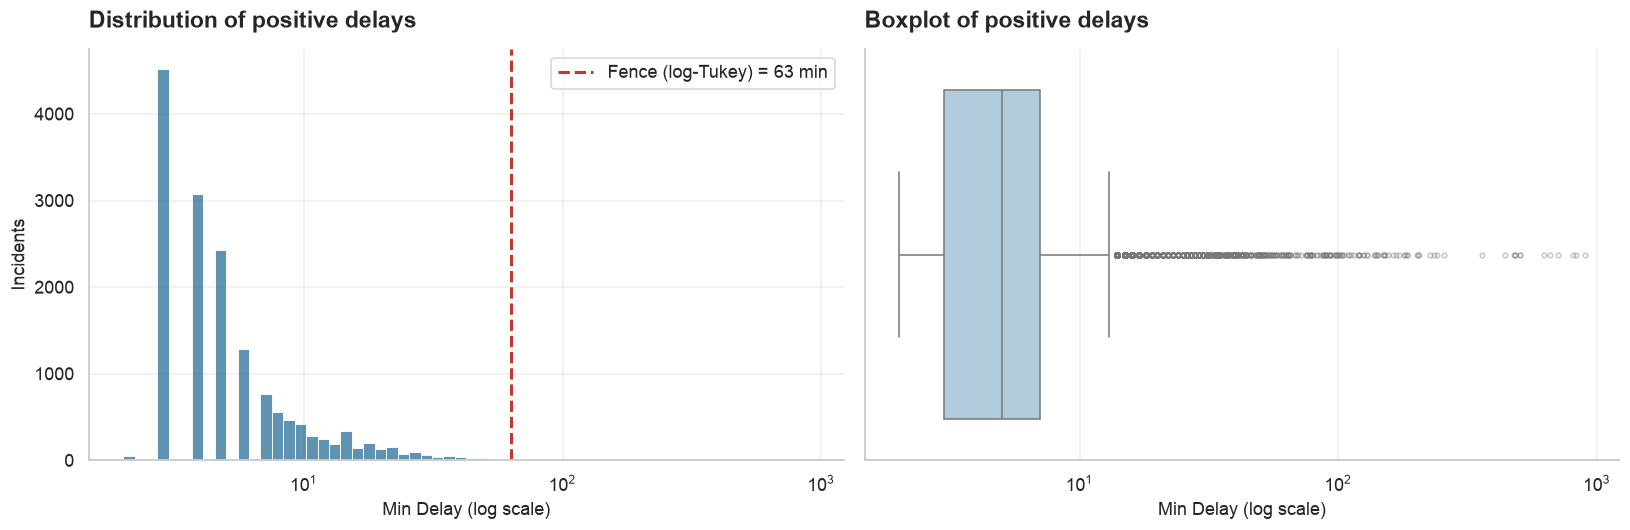

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

positive_delay = clean_df.loc[clean_df["Min Delay"] > 0, "Min Delay"]
sns.histplot(positive_delay, bins=60, log_scale=True, color="#2A6F97", ax=axes[0])
axes[0].axvline(OUTLIER_FENCES["Min Delay"], color="#C0392B", ls="--", lw=2,
                label=f"Fence (log-Tukey) = {OUTLIER_FENCES['Min Delay']:.0f} min")
axes[0].legend()
style_axis(axes[0], "Distribution of positive delays", "Min Delay (log scale)", "Incidents")

sns.boxplot(data=clean_df[clean_df["Min Delay"] > 0], x="Min Delay", color="#A9CCE3", ax=axes[1],
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
axes[1].set_xscale("log")
style_axis(axes[1], "Boxplot of positive delays", "Min Delay (log scale)")

plt.tight_layout()
plt.show()

> On a log scale the positive delays are close to normal, which is why the fence is computed there. A few extreme events hold a disproportionate share of total minutes. Dropping them would hide the worst episodes, including the winter storms.


In [19]:
print(f"Rows after preprocessing: {len(clean_df):,} "
      f"({len(clean_df) / len(raw_df):.2%} of the raw file)")

Rows after preprocessing: 45,338 (99.70% of the raw file)


---
## 3. Data Transformation

| New column | Rule |
|---|---|
| `Hour` | Hour of day, 0-23, from `Time` |
| `Is_Rush_Hour` | True on **[07:00, 09:00)** or **[16:00, 18:00)** |
| `Period_of_Day` | Overnight, morning peak, midday, afternoon peak, evening |
| `Is_Weekend` | Saturday or Sunday |
| `Has_Delay` | `Min Delay > 0` |
| `Incident_Department` | TTC department, from the code's first letter |
| `Incident_Category` | Plain-language cause group |
| `Code_Description` | Official TTC description |
| `Line_Name` | Full line name |


### 3.1 Time features


In [20]:
def is_rush_hour(moment: time) -> bool:
    return any(start <= moment < end for start, end in RUSH_HOUR_WINDOWS)


def period_of_day(hour: int) -> str:
    if hour < 6:
        return "Overnight (00-06)"
    if hour < 9:
        return "Morning peak (06-09)"
    if hour < 16:
        return "Midday (09-16)"
    if hour < 19:
        return "Afternoon peak (16-19)"
    return "Evening (19-24)"


def add_temporal_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Hour"] = out["Timestamp"].dt.hour
    out["Is_Rush_Hour"] = out["Time"].map(is_rush_hour)
    out["Period_of_Day"] = out["Hour"].map(period_of_day)
    out["Day"] = pd.Categorical(out["Day"], categories=WEEKDAY_ORDER, ordered=True)
    out["Is_Weekend"] = out["Day"].isin(["Saturday", "Sunday"])
    out["Year_Month"] = out["Date"].dt.to_period("M")
    out["Has_Delay"] = out["Min Delay"] > 0
    return out


df = add_temporal_features(clean_df)
df[["Time", "Hour", "Is_Rush_Hour", "Period_of_Day", "Day", "Is_Weekend"]].sample(6, random_state=7)

,Time,Hour,Is_Rush_Hour,Period_of_Day,Day,Is_Weekend
28069,05:39:00,5,False,Overnight (00-06),Thursday,False
44425,20:47:00,20,False,Evening (19-24),Tuesday,False
16009,06:06:00,6,False,Morning peak (06-09),Thursday,False
27988,06:02:00,6,False,Morning peak (06-09),Thursday,False
21267,23:55:00,23,False,Evening (19-24),Friday,False
8939,14:58:00,14,False,Midday (09-16),Wednesday,False


### 3.2 Grouping the delay codes

The first letter is **not** "M = mechanical, P = passengers, S = signals, E/W = weather". That reading fails against the official TTC codebook published with the open data:

| Code | Official description | That reading | Actual meaning |
|---|---|---|---|
| `SUDP` | Disorderly Patron | Signals | Passenger conduct (Security) |
| `MUIS` | Injured or ill Customer (In Station) | Mechanical | Medical emergency |
| `PUOPO` | OPTO (COMMS) Train Door Monitoring | Passengers | Door-monitoring system |
| `EUDO` | Door Problems - Faulty Equipment | Weather | Train equipment fault |

Prefix `T` (operations and crew) was also missing from that reading, and it covers thousands of rows. No `W` codes appear in this period.

The first letter is the **responsible department** (the second character, `U`, means subway):

| Prefix | TTC department | Examples |
|---|---|---|
| `E` | Equipment (Rail Cars & Shops) | brakes, doors, propulsion |
| `M` | Miscellaneous | medical, alarms, weather, fire |
| `P` | Fixed plant | track, signals, power, escalators |
| `S` | Security | disorderly patron, assault, track intrusion |
| `T` | Transportation (crew) | operator unavailable, signal violation |

`M` mixes unrelated causes, so there are two layers:

1. **`Incident_Department`**, from the official prefix.
2. **`Incident_Category`**, a theme built from the official description. This is the field used to answer "why". Codes missing from the explicit map inherit their department's theme (prefix fallback), so coverage is 100%.


In [21]:
DEPARTMENT_BY_PREFIX = {
    "E": "Equipment / Rolling Stock",
    "M": "Miscellaneous",
    "P": "Fixed Plant",
    "S": "Security",
    "T": "Operations / Crew",
}

CODE_DESCRIPTIONS = {
    "EUAC": "Air Conditioning", "EUATC": "ATC RC&S Equipment", "EUBK": "Brakes", "EUBO": "Body",
    "EUCD": "Consequential Delay (2nd Delay Same Fault)", "EUDO": "Door Problems - Faulty Equipment",
    "EUECD": "ECD / Line Mechanic Related Prob.", "EUNEA": "No Equipment Available",
    "EUNT": "Equipment - No Trouble Found", "EUO": "RC&S Other", "EUPI": "Propulsion System",
    "EUSC": "Speed Control Equipment", "EUTL": "Trainline System", "EUVE": "Work Vehicle",
    "EUYRD": "Yard/Carhouse Related Problems",
    "MUATC": "ATC Project", "MUD": "Door Problems - Passenger Related", "MUDD": "Door Problems - Debris Related",
    "MUESA": "No Operator Immediately Available", "MUFM": "Force Majeure",
    "MUFS": "Fire/Smoke Plan B - Source External to TTC", "MUGD": "Miscellaneous General Delays",
    "MUI": "Injured or ill Customer (On Train) - Transported", "MUIE": "Injured Employee",
    "MUIR": "Injured or ill Customer (On Train) - Medical Aid Refused",
    "MUIRS": "Injured or ill Customer (In Station) - Medical Aid Refused",
    "MUIS": "Injured or ill Customer (In Station) - Transported", "MULD": "Labour Dispute - Subway",
    "MUNOA": "No Operator Immediately Available - Not E.S.A. Related", "MUO": "Miscellaneous Other",
    "MUPAA": "Passenger Assistance Alarm Activated - No Trouble Found", "MUPLA": "Fire/Smoke Plan A",
    "MUPLB": "Fire/Smoke Plan B - Source TTC", "MUPR1": "Priority One - Train in Contact With Person",
    "MUSAN": "Unsanitary Vehicle", "MUSC": "Miscellaneous Speed Control",
    "MUTD": "Training Department Related Delays", "MUTO": "Misc. Transportation Other - Employee Non-Chargeable",
    "MUWEA": "Weather Reports / Related Delays", "MUWR": "Work Refusal",
    "PUATC": "ATC Signals Other", "PUCSC": "Signal Control Problem - Signals", "PUDCS": "Data Communications System Failure",
    "PUMEL": "Escalator/Elevator Incident", "PUMO": "Station Other", "PUMST": "Station Stairway Incident",
    "PUOPO": "OPTO (COMMS) Train Door Monitoring", "PUSAC": "Signals Axle Counter Block Failure",
    "PUSCA": "SCADA Related Problems", "PUSI": "Signals or Related Components Failure",
    "PUSIS": "Signals Track Weather Related", "PUSNT": "Signal Problem - No Trouble",
    "PUSRA": "Subway Radio System Fault", "PUSSW": "Track Switch Failure - Signal Related Problem",
    "PUSTC": "Signals - Track Circuit Problems", "PUSTP": "Traction Power or Related Components Failure",
    "PUSTS": "Signals - Train Stops", "PUSWZ": "Work Zone Problems - Signals", "PUTD": "Track Level Debris - Controllable",
    "PUTDN": "Debris At Track Level - Uncontrollable", "PUTIS": "Ice / Snow Related Problems", "PUTO": "T&S Other",
    "PUTOE": "T & S Operator Related Problems", "PUTR": "Rail Related Problem", "PUTS": "Structure Related Problem",
    "PUTSM": "Track Switch Failure - Track Related Problem", "PUTTP": "Traction Power Rail Related",
    "PUTWZ": "Work Zone Problems - Track",
    "SUAE": "Assault / Employee Involved", "SUAP": "Assault / Patron Involved", "SUBT": "Bomb Threat",
    "SUCOL": "Collector Booth Alarm Activated", "SUDP": "Disorderly Patron",
    "SUEAS": "Emergency Alarm Station Activation", "SUG": "Graffiti / Scratchiti", "SUO": "Passenger Other",
    "SUPOL": "Held By Police - Non-TTC Related", "SUROB": "Robbery", "SUSA": "Sexual Assault",
    "SUSP": "Suspicious Package", "SUUT": "Unauthorized at Track Level",
    "TUATC": "ATC Operator Related", "TUCC": "Transit Control Related Problems", "TUDOE": "Doors Open in Error",
    "TUKEY": "Two Drum Switch Keys Activated", "TUML": "Mainline Storage", "TUMVS": "Operator Violated Signal",
    "TUNIP": "Operator Not In Position", "TUNOA": "No Operator Immediately Available",
    "TUO": "Transportation Department - Other", "TUOPO": "OPTO Operator Related", "TUOS": "Operator Overshot Platform",
    "TUS": "Crew Unable to Maintain Schedule", "TUSC": "Operator Overspeeding",
    "TUSET": "Train Controls Improperly Shut Down", "TUST": "Storm Trains", "TUSUP": "Supervisory Error",
}

CATEGORY_BY_CODE = {
    "Medical Emergencies": {"MUI", "MUIR", "MUIRS", "MUIS", "MUIE", "MUPR1"},
    "Passenger Alarms (no fault)": {"MUPAA", "SUEAS", "SUCOL"},
    "Passenger Conduct & Security": {
        "SUDP", "SUO", "SUAP", "SUAE", "SUUT", "SUG", "SUSP", "SUBT", "SUROB", "SUSA", "SUPOL", "MUD",
    },
    "Rolling Stock & Equipment": {"MUSC", "MUDD"},
    "Signals & Control Systems": {
        "PUATC", "PUCSC", "PUCSS", "PUCBI", "PUDCS", "PUOPO", "PUSAC", "PUSBE", "PUSCA", "PUSCR", "PUSEA", "PUSI",
        "PUSIO", "PUSLC", "PUSNT", "PUSO", "PUSRA", "PUSSW", "PUSTC", "PUSTS", "PUSWZ", "PUSZC", "MUATC",
    },
    "Track, Power & Stations": {
        "PUSTP", "PUTR", "PUTS", "PUTSM", "PUTTP", "PUTTC", "PUTIJ", "PUTWZ", "PUTSC", "PUTCD", "PUTNT", "PUTO",
        "PUMEL", "PUMO", "PUMST", "MUEC", "MUODC",
    },
    "Operations & Crew": {"MUNOA", "MUESA", "MUTO", "MUCL", "MUTD", "MULD", "MUWR", "PUTOE"},
    "Weather, Fire & External": {
        "MUWEA", "MUFM", "PUTIS", "PUSIS", "MUFS", "MUPLA", "MUPLB", "MUPLC", "PUTDN",
    },
    "Cleanliness": {"MUSAN", "PUTD"},
    "Other / Unspecified": {"MUO", "MUGD", "EUCD"},
}
CODE_TO_CATEGORY = {code: category for category, codes in CATEGORY_BY_CODE.items() for code in codes}

CATEGORY_FALLBACK_BY_PREFIX = {
    "E": "Rolling Stock & Equipment",
    "P": "Track, Power & Stations",
    "S": "Passenger Conduct & Security",
    "T": "Operations & Crew",
}
OTHER_CATEGORY = "Other / Unspecified"


def incident_department(code: str) -> str:
    return DEPARTMENT_BY_PREFIX.get(str(code)[:1].upper(), "Other")


def incident_category(code: str) -> str:
    # Explicit code rule, else the department fallback, else "Other".
    code = str(code).upper().strip()
    if code in CODE_TO_CATEGORY:
        return CODE_TO_CATEGORY[code]
    return CATEGORY_FALLBACK_BY_PREFIX.get(code[:1], OTHER_CATEGORY)


def add_incident_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Code"] = out["Code"].str.upper().str.strip()
    out["Incident_Department"] = out["Code"].map(incident_department)
    out["Incident_Category"] = out["Code"].map(incident_category)
    out["Code_Description"] = out["Code"].map(CODE_DESCRIPTIONS).fillna("(not in reference codebook)")
    out["Category_Source"] = np.where(out["Code"].isin(CODE_TO_CATEGORY), "explicit rule", "prefix fallback")
    return out


df = add_incident_features(df)
print("How categories were assigned:")
print(df["Category_Source"].value_counts(normalize=True).map(pct).to_string())
print("\nMost common codes assigned by prefix fallback:")
print(df.loc[df["Category_Source"] == "prefix fallback", ["Code", "Code_Description", "Incident_Category"]]
        .value_counts().head(10).to_string())

How categories were assigned:
Category_Source
explicit rule      78.7%
prefix fallback    21.3%

Most common codes assigned by prefix fallback:
Code   Code_Description                   Incident_Category           
TUNCA  (not in reference codebook)        Operations & Crew               1162
SUL    (not in reference codebook)        Passenger Conduct & Security    1131
MUNCA  (not in reference codebook)        Other / Unspecified              958
TUSC   Operator Overspeeding              Operations & Crew                849
TUO    Transportation Department - Other  Operations & Crew                837
EUSC   Speed Control Equipment            Rolling Stock & Equipment        802
MUCP   (not in reference codebook)        Other / Unspecified              374
TUMVS  Operator Violated Signal           Operations & Crew                366
EUDO   Door Problems - Faulty Equipment   Rolling Stock & Equipment        326
TUNIP  Operator Not In Position           Operations & Crew               

> About three quarters of rows match an explicit code rule. The fallback covers (i) `T` and `E` codes whose department already states the theme (`TUSC` overspeeding, `EUSC` speed-control equipment) and (ii) newer codes absent from the reference codebook (`TUNCA`, `SUL`, `MUNCA`, `MUINF`), which inherit the department theme. Undescribed `M` codes go to *Other*, with no invented meaning.


### 3.3 Line names and the analysis table


In [22]:
def add_line_names(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Line_Name"] = out["Line_Std"].map(LINES_IN_SCOPE).fillna(MULTI_LINE_LABEL)
    return out


ANALYTICAL_COLUMNS = [
    "_id", "Timestamp", "Date", "Time", "Day", "Hour", "Is_Rush_Hour", "Period_of_Day", "Is_Weekend",
    "Year_Month", "Station", "Station_Std", "Is_Station", "Line_Std", "Line_Name", "Bound", "Vehicle",
    "Code", "Code_Description", "Incident_Department", "Incident_Category",
    "Min Delay", "Min Gap", "Min Delay_Capped", "Min Gap_Capped", "Has_Delay", "Is_Extreme_Delay",
]

df = add_line_names(df)[ANALYTICAL_COLUMNS]
single_line_df = df[df["Line_Std"].isin(LINES_IN_SCOPE)]

print(f"Analysis table: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Single-line incidents: {len(single_line_df):,} | Multi-line: {(df['Line_Std'] == 'MULTI').sum():,}")
df.head()

Analysis table: 45,338 rows x 27 columns
Single-line incidents: 44,743 | Multi-line: 595


,_id,Timestamp,Date,Time,Day,Hour,Is_Rush_Hour,Period_of_Day,Is_Weekend,Year_Month,Station,Station_Std,Is_Station,Line_Std,Line_Name,Bound,Vehicle,Code,Code_Description,Incident_Department,Incident_Category,Min Delay,Min Gap,Min Delay_Capped,Min Gap_Capped,Has_Delay,Is_Extreme_Delay
0,1,2025-01-01 02:10:00,2025-01-01,02:10:00,Wednesday,2,False,Overnight (00-06),False,2025-01,BATHURST STATION,BATHURST,True,BD,Bloor-Danforth,E,5227,MUSAN,Unsanitary Vehicle,Miscellaneous,Cleanliness,5,9,5.00,9.00,True,False
1,2,2025-01-01 02:30:00,2025-01-01,02:30:00,Wednesday,2,False,Overnight (00-06),False,2025-01,DUNDAS STATION,TMU,True,YU,Yonge-University,Unknown,<NA>,MUIRS,Injured or ill Customer (In Station) - Medical...,Miscellaneous,Medical Emergencies,0,0,0.00,0.00,False,False
2,3,2025-01-01 02:32:00,2025-01-01,02:32:00,Wednesday,2,False,Overnight (00-06),False,2025-01,BROADVIEW STATION,BROADVIEW,True,BD,Bloor-Danforth,E,<NA>,PUMST,Station Stairway Incident,Fixed Plant,"Track, Power & Stations",0,0,0.00,0.00,False,False
3,4,2025-01-01 02:58:00,2025-01-01,02:58:00,Wednesday,2,False,Overnight (00-06),False,2025-01,KEELE STATION,KEELE,True,BD,Bloor-Danforth,W,5293,EUSC,Speed Control Equipment,Equipment / Rolling Stock,Rolling Stock & Equipment,0,0,0.00,0.00,False,False
4,5,2025-01-01 02:58:00,2025-01-01,02:58:00,Wednesday,2,False,Overnight (00-06),False,2025-01,COXWELL STATION,COXWELL,True,BD,Bloor-Danforth,Unknown,<NA>,SUAE,Assault / Employee Involved,Security,Passenger Conduct & Security,0,0,0.00,0.00,False,False


---
## 4. Data Mining

The mining is descriptive: counts, rankings and normalized comparisons. Two measures run through every table:

- **Frequency** (incident count): how often the system fails.
- **Severity** (`Min Delay` minutes): what each failure costs the passenger.

A cause can be common and mild (alarms with no fault) or rare and severe (snow). `summarize` computes the same indicators for any grouping.


In [23]:
def summarize(df: pd.DataFrame, by) -> pd.DataFrame:
    # Frequency and severity indicators for any grouping.
    summary = (
        df.groupby(by, observed=True)
          .agg(
              Incidents=("Code", "size"),
              Delay_Minutes=("Min Delay", "sum"),
              Mean_Delay=("Min Delay", "mean"),
              Robust_Mean_Delay=("Min Delay_Capped", "mean"),
              Mean_Gap=("Min Gap", "mean"),
              Pct_With_Delay=("Has_Delay", "mean"),
          )
    )
    summary["Pct_Incidents"] = summary["Incidents"] / summary["Incidents"].sum()
    summary["Pct_Minutes"] = summary["Delay_Minutes"] / summary["Delay_Minutes"].sum()
    return summary


def show(summary: pd.DataFrame):
    # Readable percentages and thousands.
    return summary.style.format({
        "Incidents": "{:,.0f}", "Delay_Minutes": "{:,.0f}", "Mean_Delay": "{:.2f}",
        "Robust_Mean_Delay": "{:.2f}", "Mean_Gap": "{:.2f}", "Pct_With_Delay": "{:.1%}",
        "Pct_Incidents": "{:.1%}", "Pct_Minutes": "{:.1%}",
    }).background_gradient(subset=["Incidents", "Delay_Minutes"], cmap="Blues")

### 4.1 Question 1: volume and main causes


In [24]:
category_summary = summarize(df, "Incident_Category").sort_values("Incidents", ascending=False)
show(category_summary)

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes
Incident_Category,,,,,,,,
Passenger Conduct & Security,"12,865","31,451",2.44,2.42,3.66,31.3%,28.4%,25.8%
Medical Emergencies,"8,913","17,764",1.99,1.86,2.79,21.4%,19.7%,14.6%
Operations & Crew,"5,015","11,887",2.37,2.36,3.76,43.6%,11.1%,9.7%
Rolling Stock & Equipment,"4,253","12,575",2.96,2.79,4.26,44.4%,9.4%,10.3%
Other / Unspecified,"3,417","2,954",0.86,0.86,1.21,14.6%,7.5%,2.4%
"Track, Power & Stations","3,416","10,821",3.17,2.53,2.51,25.5%,7.5%,8.9%
Signals & Control Systems,"3,410","11,901",3.49,3.28,5.11,51.4%,7.5%,9.8%
Passenger Alarms (no fault),"2,499","6,495",2.60,2.60,4.71,55.2%,5.5%,5.3%
Cleanliness,785,"3,304",4.21,4.21,7.68,93.0%,1.7%,2.7%


In [25]:
department_summary = summarize(df, "Incident_Department").sort_values("Incidents", ascending=False)
show(department_summary)

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes
Incident_Department,,,,,,,,
Miscellaneous,"18,591","41,812",2.25,2.01,3.32,30.9%,41.0%,34.3%
Security,"12,736","31,695",2.49,2.47,3.69,30.9%,28.1%,26.0%
Fixed Plant,"7,146","28,056",3.93,3.08,4.22,39.6%,15.8%,23.0%
Operations / Crew,"4,339","9,786",2.26,2.25,3.51,40.4%,9.6%,8.0%
Equipment / Rolling Stock,"2,522","10,604",4.20,3.92,5.86,60.8%,5.6%,8.7%
Other,4,0,0.00,0.00,0.00,0.0%,0.0%,0.0%


In [26]:
top_codes = (
    summarize(df, ["Code", "Code_Description", "Incident_Category"])
      .sort_values("Incidents", ascending=False)
      .head(15)
)
show(top_codes)

,,,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes
Code,Code_Description,Incident_Category,,,,,,,,
SUDP,Disorderly Patron,Passenger Conduct & Security,"5,166","12,098",2.34,2.33,3.80,37.1%,11.4%,9.9%
MUIS,Injured or ill Customer (In Station) - Transported,Medical Emergencies,"4,260",369,0.09,0.09,0.13,1.1%,9.4%,0.3%
SUO,Passenger Other,Passenger Conduct & Security,"3,268","6,305",1.93,1.89,2.84,22.6%,7.2%,5.2%
MUPAA,Passenger Assistance Alarm Activated - No Trouble Found,Passenger Alarms (no fault),"2,405","5,396",2.24,2.24,4.30,53.8%,5.3%,4.4%
PUOPO,OPTO (COMMS) Train Door Monitoring,Signals & Control Systems,"2,336","5,355",2.29,2.29,3.97,46.7%,5.2%,4.4%
MUIRS,Injured or ill Customer (In Station) - Medical Aid Refused,Medical Emergencies,"2,046",300,0.15,0.15,0.25,2.6%,4.5%,0.2%
MUIR,Injured or ill Customer (On Train) - Medical Aid Refused,Medical Emergencies,"1,574","8,501",5.40,5.40,8.33,77.3%,3.5%,7.0%
MUSC,Miscellaneous Speed Control,Rolling Stock & Equipment,"1,455",552,0.38,0.38,0.73,9.2%,3.2%,0.5%
MUO,Miscellaneous Other,Other / Unspecified,"1,414","2,169",1.53,1.53,2.12,25.6%,3.1%,1.8%


> **Question 1**
>
> - The largest source of incidents is people. **Passenger Conduct & Security** is about **28% of incidents and 26% of minutes**. With **Medical Emergencies** (~20%), nearly half of all rows involve a person on the system.
> - **`SUDP` (Disorderly Patron)** is the single most common code (~5.2k rows, ~11%) and the code with the most minutes (~12k).
> - Frequency and impact diverge. `MUIS` (ill customer in the station) is the 2nd most common code, yet only ~1% of those rows delay service (mean 0.09 min). `MUIR` (ill customer **on the train**, aid refused) averages 5.4 min, because the train is held at the platform.
> - Technical causes (rolling stock, signals, track and power) are ~25% of incidents and ~29% of minutes: less common, costlier each time.
> - The official *Miscellaneous* department holds 41% of rows, which is why the theme layer exists. The prefix alone would mix medical calls, alarms, weather and cleaning.


### 4.2 Question 2: time patterns

#### 4.2.1 Weekday

The window does not contain the same number of each weekday, so the table also reports the **mean per calendar day** (total divided by how many dates fell on that weekday).


In [27]:
days_in_period = df.groupby("Day", observed=True)["Date"].nunique().rename("Days_in_Period")
weekday_summary = summarize(df, "Day").join(days_in_period)
weekday_summary["Incidents_per_Day"] = weekday_summary["Incidents"] / weekday_summary["Days_in_Period"]
weekday_summary["Minutes_per_Day"] = weekday_summary["Delay_Minutes"] / weekday_summary["Days_in_Period"]

show(weekday_summary).format({"Incidents_per_Day": "{:.1f}", "Minutes_per_Day": "{:,.0f}"}, subset=["Incidents_per_Day", "Minutes_per_Day"])

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes,Days_in_Period,Incidents_per_Day,Minutes_per_Day
Day,,,,,,,,,,,
Monday,"6,776","18,572",2.74,2.34,3.39,34.4%,14.9%,15.2%,87,77.9,213
Tuesday,"6,724","17,493",2.60,2.43,3.52,36.0%,14.8%,14.3%,86,78.2,203
Wednesday,"6,931","17,592",2.54,2.34,3.63,35.5%,15.3%,14.4%,87,79.7,202
Thursday,"7,054","18,357",2.60,2.50,3.67,35.4%,15.6%,15.1%,87,81.1,211
Friday,"6,960","17,917",2.57,2.44,3.58,35.0%,15.4%,14.7%,87,80.0,206
Saturday,"5,735","14,167",2.47,2.40,3.81,33.7%,12.6%,11.6%,87,65.9,163
Sunday,"5,158","17,855",3.46,2.64,4.76,33.4%,11.4%,14.6%,87,59.3,205


In [28]:
weekday_rate = weekday_summary["Incidents_per_Day"]
weekend_mask = weekday_rate.index.isin(["Saturday", "Sunday"])
print(f"Mean incidents/day, weekdays: {weekday_rate[~weekend_mask].mean():.1f} | "
      f"weekend: {weekday_rate[weekend_mask].mean():.1f} "
      f"({weekday_rate[~weekend_mask].mean() / weekday_rate[weekend_mask].mean() - 1:+.1%} on weekdays)")

Mean incidents/day, weekdays: 79.4 | weekend: 62.6 (+26.8% on weekdays)


#### 4.2.2 Hour of day, and rush hour vs off-peak

Raw totals would favor off-peak: rush hour is 4 hours a day, off-peak is the other 20, including the closed hours. The comparison below is a **rate per hour of window**, and "off-peak" is limited to hours with regular service (06:00-01:00).


In [29]:
hourly_summary = summarize(df, "Hour").reindex(range(24), fill_value=0)
hourly_summary["Is_Rush_Hour"] = [is_rush_hour(time(h, 0)) for h in hourly_summary.index]
show(hourly_summary.drop(columns="Is_Rush_Hour"))

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes
Hour,,,,,,,,
0,"1,604","3,772",2.35,2.30,3.95,30.2%,3.5%,3.1%
1,"1,679","3,860",2.30,2.30,3.66,27.4%,3.7%,3.2%
2,988,721,0.73,0.73,0.97,6.9%,2.2%,0.6%
3,260,89,0.34,0.34,0.40,3.1%,0.6%,0.1%
4,212,548,2.58,0.89,2.16,4.2%,0.5%,0.4%
5,"1,588","8,368",5.27,3.87,2.21,41.1%,3.5%,6.9%
6,"2,033","7,424",3.65,3.11,3.69,49.5%,4.5%,6.1%
7,"2,067","4,457",2.16,2.13,2.96,36.7%,4.6%,3.7%
8,"2,664","6,619",2.48,2.43,3.28,38.0%,5.9%,5.4%


In [30]:
SERVICE_HOURS = set(range(6, 24)) | {0, 1}


def rush_vs_normal(df: pd.DataFrame, service_hours=SERVICE_HOURS) -> pd.DataFrame:
    # Rush vs off-peak as an hourly rate, so the windows' different lengths do not bias the comparison.
    in_service = df[df["Hour"].isin(service_hours)]
    n_days = df["Date"].nunique()
    window_hours = {True: 4, False: len(service_hours) - 4}
    result = summarize(in_service, "Is_Rush_Hour")
    result["Window_Hours"] = [window_hours[flag] for flag in result.index]
    result["Incidents_per_Hour"] = result["Incidents"] / (result["Window_Hours"] * n_days)
    result["Minutes_per_Hour"] = result["Delay_Minutes"] / (result["Window_Hours"] * n_days)
    return result.rename(index={True: "Rush Hour", False: "Off-peak"})


rush_summary = rush_vs_normal(df)
show(rush_summary).format({"Incidents_per_Hour": "{:.2f}", "Minutes_per_Hour": "{:.2f}"}, subset=["Incidents_per_Hour", "Minutes_per_Hour"])

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes,Window_Hours,Incidents_per_Hour,Minutes_per_Hour
Is_Rush_Hour,,,,,,,,,,,
Off-peak,"32,520","86,309",2.65,2.44,3.93,34.7%,76.9%,76.9%,16,3.34,8.87
Rush Hour,"9,770","25,918",2.65,2.47,3.69,38.7%,23.1%,23.1%,4,4.02,10.66


In [31]:
rush_weekday = rush_vs_normal(df[~df["Is_Weekend"]])
rush_lift = rush_summary.loc["Rush Hour", "Incidents_per_Hour"] / rush_summary.loc["Off-peak", "Incidents_per_Hour"] - 1
rush_lift_weekday = rush_weekday.loc["Rush Hour", "Incidents_per_Hour"] / rush_weekday.loc["Off-peak", "Incidents_per_Hour"] - 1
minutes_lift = rush_summary.loc["Rush Hour", "Minutes_per_Hour"] / rush_summary.loc["Off-peak", "Minutes_per_Hour"] - 1

print(f"Incidents/hour, rush vs off-peak (all days): {rush_lift:+.1%}")
print(f"Incidents/hour, rush vs off-peak (weekdays only): {rush_lift_weekday:+.1%}")
print(f"Delay minutes/hour, rush vs off-peak           : {minutes_lift:+.1%}")
print(f"Mean delay per incident, rush: {rush_summary.loc['Rush Hour', 'Mean_Delay']:.2f} min | "
      f"off-peak: {rush_summary.loc['Off-peak', 'Mean_Delay']:.2f} min")

Incidents/hour, rush vs off-peak (all days): +20.2%
Incidents/hour, rush vs off-peak (weekdays only): +25.7%
Delay minutes/hour, rush vs off-peak           : +20.1%
Mean delay per incident, rush: 2.65 min | off-peak: 2.65 min


#### 4.2.3 Weekday x hour

Each cell is the **mean incident count per calendar day** for that weekday and hour. Section 5 plots this matrix.


In [32]:
weekday_hour_matrix = (
    df.pivot_table(index="Day", columns="Hour", values="Code", aggfunc="size", fill_value=0, observed=True)
      .reindex(columns=range(24), fill_value=0)
      .div(days_in_period, axis=0)
)
weekday_hour_matrix.round(2)

Hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Day,,,,,,,,,,,,,,,,,,,,,,,,
Monday,2.26,2.70,1.67,0.55,0.53,3.47,4.10,3.70,5.20,3.76,3.06,2.76,3.54,3.45,3.53,3.77,4.02,4.28,4.18,3.13,2.98,3.20,4.22,3.84
Tuesday,2.45,2.56,1.49,0.37,0.45,2.69,4.31,4.00,4.80,3.86,3.14,3.14,3.55,3.42,3.20,3.76,4.60,4.80,3.99,3.15,3.48,3.29,4.19,3.50
Wednesday,2.64,2.71,1.70,0.39,0.33,2.57,4.11,3.87,4.69,3.78,2.89,3.30,3.29,3.32,3.95,4.49,4.69,4.49,4.16,3.33,3.47,3.28,4.45,3.74
Thursday,2.95,2.70,1.53,0.36,0.33,2.94,3.71,4.46,4.97,3.77,3.29,3.03,3.45,3.39,3.79,3.93,5.05,4.75,4.23,3.25,3.52,3.29,4.71,3.68
Friday,2.79,3.16,1.44,0.54,0.36,3.51,3.87,3.80,4.03,3.38,2.95,3.34,3.97,3.37,3.91,3.93,3.92,4.26,4.20,3.17,3.25,3.72,4.66,4.46
Saturday,2.76,2.79,1.83,0.38,0.28,2.82,2.87,1.94,2.09,2.28,2.31,3.54,3.02,3.39,3.14,2.95,3.16,3.43,3.47,3.01,3.38,3.23,4.62,3.23
Sunday,2.60,2.70,1.72,0.40,0.16,0.29,0.43,2.02,4.90,2.34,2.57,2.97,2.51,2.98,2.93,3.03,3.36,3.22,3.18,3.02,2.51,2.80,4.07,2.57


In [33]:
peak_cells = weekday_hour_matrix.stack().sort_values(ascending=False).head(8)
print("Busiest weekday x hour cells (mean incidents per day):")
for (day, hour), value in peak_cells.items():
    print(f"  {day:<9} {hour:02d}:00  {value:.2f}")

Busiest weekday x hour cells (mean incidents per day):
  Monday    08:00  5.20
  Thursday  16:00  5.05
  Thursday  08:00  4.97
  Sunday    08:00  4.90
  Tuesday   08:00  4.80
  Tuesday   17:00  4.80
  Thursday  17:00  4.75
  Thursday  22:00  4.71


> **Question 2**
>
> - Weekdays run about **27% higher** than weekends (~79 vs ~63 incidents per day). Thursday is the busiest (~81 per day).
> - Sunday has the fewest incidents and the **highest mean delay** (3.46 min vs ~2.6). The two largest snow events (2025-02-16 and 2026-01-25/26) started on Sundays, which is why robust means are reported alongside raw means.
> - Rush hour is more exposed in **frequency**, with the same severity. Per hour of window it has **+20% incidents** (+26% on weekdays only) and +20% delay minutes. Mean delay per incident is **2.65 min in both windows**.
> - The hourly curve has three peaks: 08:00, 16:00-17:00, and **22:00**, the single busiest hour. The 22:00 peak is mostly generic or administrative codes (`MUO`, `MUINF`), consistent with early closings for night work, not with a surge in failures.
> - The opening hour is fragile. At 05:00-06:00 the leading codes are door monitoring (`PUOPO`), leftover work zones (`PUTWZ`) and crew not in place (`TUNCA`, `MUNCA`). On Sunday the jump is at **08:00**, matching the later start of service.


### 4.3 Question 3: lines and stations

#### 4.3.1 Lines

Totals are also divided by station count (38 on YU, 31 on BD, 5 on SHP). Sheppard is much smaller, so raw totals would always rank it last.


In [34]:
line_summary = summarize(df, "Line_Name").sort_values("Delay_Minutes", ascending=False)
stations_per_line = {LINES_IN_SCOPE[code]: len(stations) for code, stations in OFFICIAL_STATIONS.items()}
line_summary["Stations"] = line_summary.index.map(stations_per_line)
line_summary["Incidents_per_Station"] = line_summary["Incidents"] / line_summary["Stations"]
line_summary["Minutes_per_Station"] = line_summary["Delay_Minutes"] / line_summary["Stations"]

show(line_summary).format(
    {"Stations": "{:.0f}", "Incidents_per_Station": "{:,.1f}", "Minutes_per_Station": "{:,.1f}"},
    subset=["Stations", "Incidents_per_Station", "Minutes_per_Station"], na_rep="-",
)

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes,Stations,Incidents_per_Station,Minutes_per_Station
Line_Name,,,,,,,,,,,
Yonge-University,"23,183","65,486",2.82,2.56,3.91,37.3%,51.1%,53.7%,38,610.1,"1,723.3"
Bloor-Danforth,"19,795","51,513",2.60,2.36,3.57,33.0%,43.7%,42.2%,31,638.5,"1,661.7"
Sheppard,"1,765","4,954",2.81,2.51,4.31,35.6%,3.9%,4.1%,5,353.0,990.8
Multi-line,595,0,0.00,0.00,0.00,0.0%,1.3%,0.0%,-,-,-


In [35]:
line_category_minutes = (
    single_line_df.pivot_table(index="Incident_Category", columns="Line_Name", values="Min Delay",
                               aggfunc="sum", fill_value=0)
)
line_category_share = line_category_minutes.div(line_category_minutes.sum(axis=0), axis=1)
line_category_share.sort_values("Yonge-University", ascending=False).style.format("{:.1%}").background_gradient(cmap="Oranges")

Line_Name,Bloor-Danforth,Sheppard,Yonge-University
Incident_Category,,,
Passenger Conduct & Security,26.0%,14.8%,26.5%
Medical Emergencies,15.4%,5.7%,14.6%
Signals & Control Systems,6.3%,24.9%,11.3%
"Weather, Fire & External",11.2%,1.8%,10.6%
"Track, Power & Stations",7.2%,16.9%,9.6%
Rolling Stock & Equipment,13.7%,10.6%,7.7%
Passenger Alarms (no fault),2.8%,1.5%,7.6%
Operations & Crew,12.4%,19.3%,6.9%
Cleanliness,2.5%,2.2%,2.9%


#### 4.3.2 Most critical stations


In [36]:
station_summary = summarize(df[df["Is_Station"]], "Station_Std")
top10_by_minutes = station_summary.nlargest(10, "Delay_Minutes")
top10_by_frequency = station_summary.nlargest(10, "Incidents")

print("Top 10 by accumulated delay minutes:")
display(show(top10_by_minutes))

Top 10 by accumulated delay minutes:


,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes
Station_Std,,,,,,,,
BLOOR-YONGE,"2,995","5,211",1.74,1.72,2.59,28.0%,7.0%,4.4%
KIPLING,"1,743","4,507",2.59,2.28,3.89,41.0%,4.0%,3.8%
EGLINTON,"1,103","4,039",3.66,2.90,4.64,41.0%,2.6%,3.4%
KENNEDY,"1,863","3,834",2.06,1.98,3.29,36.4%,4.3%,3.2%
ST GEORGE,"1,390","3,754",2.70,2.66,3.84,39.6%,3.2%,3.2%
FINCH,"1,822","3,436",1.89,1.79,2.94,33.4%,4.2%,2.9%
SHEPPARD-YONGE,"1,055","3,351",3.18,2.88,4.87,39.1%,2.4%,2.8%
WILSON,930,"3,195",3.44,3.34,4.60,55.6%,2.2%,2.7%
VICTORIA PARK,797,"3,097",3.89,2.97,5.12,33.1%,1.9%,2.6%


In [37]:
print("Top 10 by incident frequency:")
show(top10_by_frequency)

Top 10 by incident frequency:


,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes
Station_Std,,,,,,,,
BLOOR-YONGE,"2,995","5,211",1.74,1.72,2.59,28.0%,7.0%,4.4%
KENNEDY,"1,863","3,834",2.06,1.98,3.29,36.4%,4.3%,3.2%
FINCH,"1,822","3,436",1.89,1.79,2.94,33.4%,4.2%,2.9%
KIPLING,"1,743","4,507",2.59,2.28,3.89,41.0%,4.0%,3.8%
ST GEORGE,"1,390","3,754",2.70,2.66,3.84,39.6%,3.2%,3.2%
VAUGHAN METROPOLITAN CENTRE,"1,181","1,954",1.65,1.65,2.83,32.5%,2.7%,1.7%
UNION,"1,157","2,507",2.17,2.07,2.73,30.0%,2.7%,2.1%
EGLINTON,"1,103","4,039",3.66,2.90,4.64,41.0%,2.6%,3.4%
SHEPPARD-YONGE,"1,055","3,351",3.18,2.88,4.87,39.1%,2.4%,2.8%


In [38]:
in_both = top10_by_minutes.index.intersection(top10_by_frequency.index)
print(f"Stations on both rankings ({len(in_both)}): {', '.join(in_both)}")

top10_share = top10_by_frequency["Incidents"].sum() / station_summary["Incidents"].sum()
print(f"The 10 most frequent stations hold {top10_share:.1%} of incidents "
      f"attributed to a station ({len(station_summary)} stations).")

top_station_causes = (
    df[df["Station_Std"].isin(top10_by_frequency.index)]
      .groupby("Station_Std")["Incident_Category"]
      .agg(lambda s: s.value_counts().index[0])
      .rename("Top_Cause")
)
top_station_causes.to_frame()

Stations on both rankings (7): BLOOR-YONGE, KIPLING, EGLINTON, KENNEDY, ST GEORGE, FINCH, SHEPPARD-YONGE
The 10 most frequent stations hold 35.5% of incidents attributed to a station (70 stations).


,Top_Cause
Station_Std,
BLOOR-YONGE,Passenger Conduct & Security
EGLINTON,Passenger Conduct & Security
FINCH,Medical Emergencies
KENNEDY,Medical Emergencies
KIPLING,Operations & Crew
SHEPPARD-YONGE,Passenger Conduct & Security
SPADINA,Passenger Conduct & Security
ST GEORGE,Passenger Conduct & Security
UNION,Passenger Conduct & Security


> **Question 3**
>
> - **Yonge-University** leads on both volume and minutes: ~51% of incidents and ~54% of minutes (~65k). Bloor-Danforth is ~44% / ~42%. Sheppard is ~4%.
> - Per station, YU and BD are level at ~1.7k minutes each, and BD has slightly more incidents per station. Sheppard is about 40% lower per station, but with only 5 stations a single fault stops the whole line.
> - The cause mix differs. On YU and BD, passenger conduct is ~26% of minutes. On **Sheppard**, signals (~25%) and crew (~19%) lead.
> - The ~595 multi-line rows contribute **0 delay minutes**. They are administrative notices (`MUO`, `MUINF`), which is why they were not forced onto one line.
> - **Bloor-Yonge** tops both rankings (~3.0k incidents, ~5.2k minutes). It is the main YU-BD interchange. Seven stations appear on both lists: Bloor-Yonge, Kipling, Eglinton, Kennedy, St George, Finch, Sheppard-Yonge.
> - Terminals (Kipling, Kennedy, Finch, Vaughan MC) and interchanges (St George, Sheppard-Yonge, Spadina) dominate. At terminals the leading themes are medical calls and crew moves.
> - The 10 most frequent stations hold **~35%** of station-attributed incidents, out of 70 stations.
> - Severity is uneven. Sheppard West has relatively few incidents and the highest mean delay in the top 10 (~5.1 min), pulled up by extreme weather.


### 4.4 Question 4: passenger impact

The delay distribution is skewed, so three averages are reported:

- **Mean per incident**, including zeros: the expected cost of a logged incident.
- **Conditional mean**, delayed incidents only: how long a delay lasts once it happens.
- **Conditional median** and **winsorized mean**: a typical value, less sensitive to the extreme tail.


In [39]:
def impact_metrics(df: pd.DataFrame) -> pd.Series:
    with_delay = df[df["Has_Delay"]]
    return pd.Series({
        "Incidents": len(df),
        "Pct with delay": df["Has_Delay"].mean(),
        "Mean Min Delay (all)": df["Min Delay"].mean(),
        "Mean Min Gap (all)": df["Min Gap"].mean(),
        "Mean Min Delay (delayed only)": with_delay["Min Delay"].mean(),
        "Mean Min Gap (delayed only)": with_delay["Min Gap"].mean(),
        "Median Min Delay (delayed only)": with_delay["Min Delay"].median(),
        "Robust mean Min Delay (delayed only)": with_delay["Min Delay_Capped"].mean(),
        "Total delay minutes": df["Min Delay"].sum(),
    })


impact_overall = impact_metrics(df).to_frame("TTC system")
impact_by_line = df.groupby("Line_Name").apply(impact_metrics, include_groups=False).T
impact_table = impact_overall.join(impact_by_line)
impact_table

,TTC system,Bloor-Danforth,Multi-line,Sheppard,Yonge-University
Incidents,"45,338.00","19,795.00",595.00,"1,765.00","23,183.00"
Pct with delay,0.35,0.33,0.00,0.36,0.37
Mean Min Delay (all),2.69,2.60,0.00,2.81,2.82
Mean Min Gap (all),3.73,3.57,0.00,4.31,3.91
Mean Min Delay (delayed only),7.72,7.89,NaN,7.89,7.58
Mean Min Gap (delayed only),10.69,10.83,NaN,12.12,10.48
Median Min Delay (delayed only),5.00,4.00,NaN,5.00,5.00
Robust mean Min Delay (delayed only),6.99,7.14,NaN,7.06,6.88
Total delay minutes,"121,953.00","51,513.00",0.00,"4,954.00","65,486.00"


In [40]:
category_impact = summarize(df, "Incident_Category").sort_values("Delay_Minutes", ascending=False)
category_impact["Minutes_per_Incident"] = category_impact["Delay_Minutes"] / category_impact["Incidents"]
category_impact["Severity_Index"] = category_impact["Pct_Minutes"] / category_impact["Pct_Incidents"]

show(category_impact).format({"Minutes_per_Incident": "{:.2f}", "Severity_Index": "{:.2f}"},
                             subset=["Minutes_per_Incident", "Severity_Index"])

,Incidents,Delay_Minutes,Mean_Delay,Robust_Mean_Delay,Mean_Gap,Pct_With_Delay,Pct_Incidents,Pct_Minutes,Minutes_per_Incident,Severity_Index
Incident_Category,,,,,,,,,,
Passenger Conduct & Security,"12,865","31,451",2.44,2.42,3.66,31.3%,28.4%,25.8%,2.44,0.91
Medical Emergencies,"8,913","17,764",1.99,1.86,2.79,21.4%,19.7%,14.6%,1.99,0.74
"Weather, Fire & External",765,"12,801",16.73,8.38,15.73,72.5%,1.7%,10.5%,16.73,6.22
Rolling Stock & Equipment,"4,253","12,575",2.96,2.79,4.26,44.4%,9.4%,10.3%,2.96,1.10
Signals & Control Systems,"3,410","11,901",3.49,3.28,5.11,51.4%,7.5%,9.8%,3.49,1.30
Operations & Crew,"5,015","11,887",2.37,2.36,3.76,43.6%,11.1%,9.7%,2.37,0.88
"Track, Power & Stations","3,416","10,821",3.17,2.53,2.51,25.5%,7.5%,8.9%,3.17,1.18
Passenger Alarms (no fault),"2,499","6,495",2.60,2.60,4.71,55.2%,5.5%,5.3%,2.60,0.97
Cleanliness,785,"3,304",4.21,4.21,7.68,93.0%,1.7%,2.7%,4.21,1.56


**Severity index** = share of minutes / share of incidents. Above 1, the cause costs more than its frequency suggests. Below 1, it is common and comparatively cheap.


In [41]:
extreme_share = df.loc[df["Is_Extreme_Delay"], "Min Delay"].sum() / df["Min Delay"].sum()
extreme_by_category = (df[df["Is_Extreme_Delay"]].groupby("Incident_Category")["Min Delay"]
                         .agg(["size", "sum"]).sort_values("sum", ascending=False))
print(f"Extreme events: {df['Is_Extreme_Delay'].sum()} rows ({df['Is_Extreme_Delay'].mean():.2%}) "
      f"hold {extreme_share:.1%} of all delay minutes.")
extreme_by_category.rename(columns={"size": "Extreme_Events", "sum": "Minutes"})

Extreme events: 106 rows (0.23%) hold 14.9% of all delay minutes.


,Extreme_Events,Minutes
Incident_Category,,
"Weather, Fire & External",22,7777
"Track, Power & Stations",28,3950
Medical Emergencies,19,2368
Rolling Stock & Equipment,14,1605
Signals & Control Systems,14,1590
Passenger Conduct & Security,8,798
Operations & Crew,1,93


> **Question 4**
>
> - Across all incidents the means are **~2.7 min of delay** and **~3.7 min of gap**. Only **~35%** of incidents actually delay service. When they do, the mean delay is **~7.7 min** (median 5) and the mean gap is **~10.7 min**.
> - **Weather, Fire & External** is the most severe group: **1.7% of incidents, 10.5% of minutes** (severity index **6.2**), with a mean of ~16.7 min. The two snow episodes alone account for ~7.9k minutes over three days, more than 10 times a typical day (~200 min).
> - Cleanliness (1.6), signals (1.3), track and power (1.2) and rolling stock (1.1) also sit above 1.
> - Passenger conduct leads in absolute minutes (~31k) with a below-average index (0.91): the issue is volume.
> - Extreme delays (over 63 min, 0.23% of rows) hold **~15% of all minutes**, mostly weather and track.


---
## 5. Evaluation and Interpretation

The charts below restate the mined patterns. Each note says what the figure shows for TTC operations.


### 5.1 Main causes


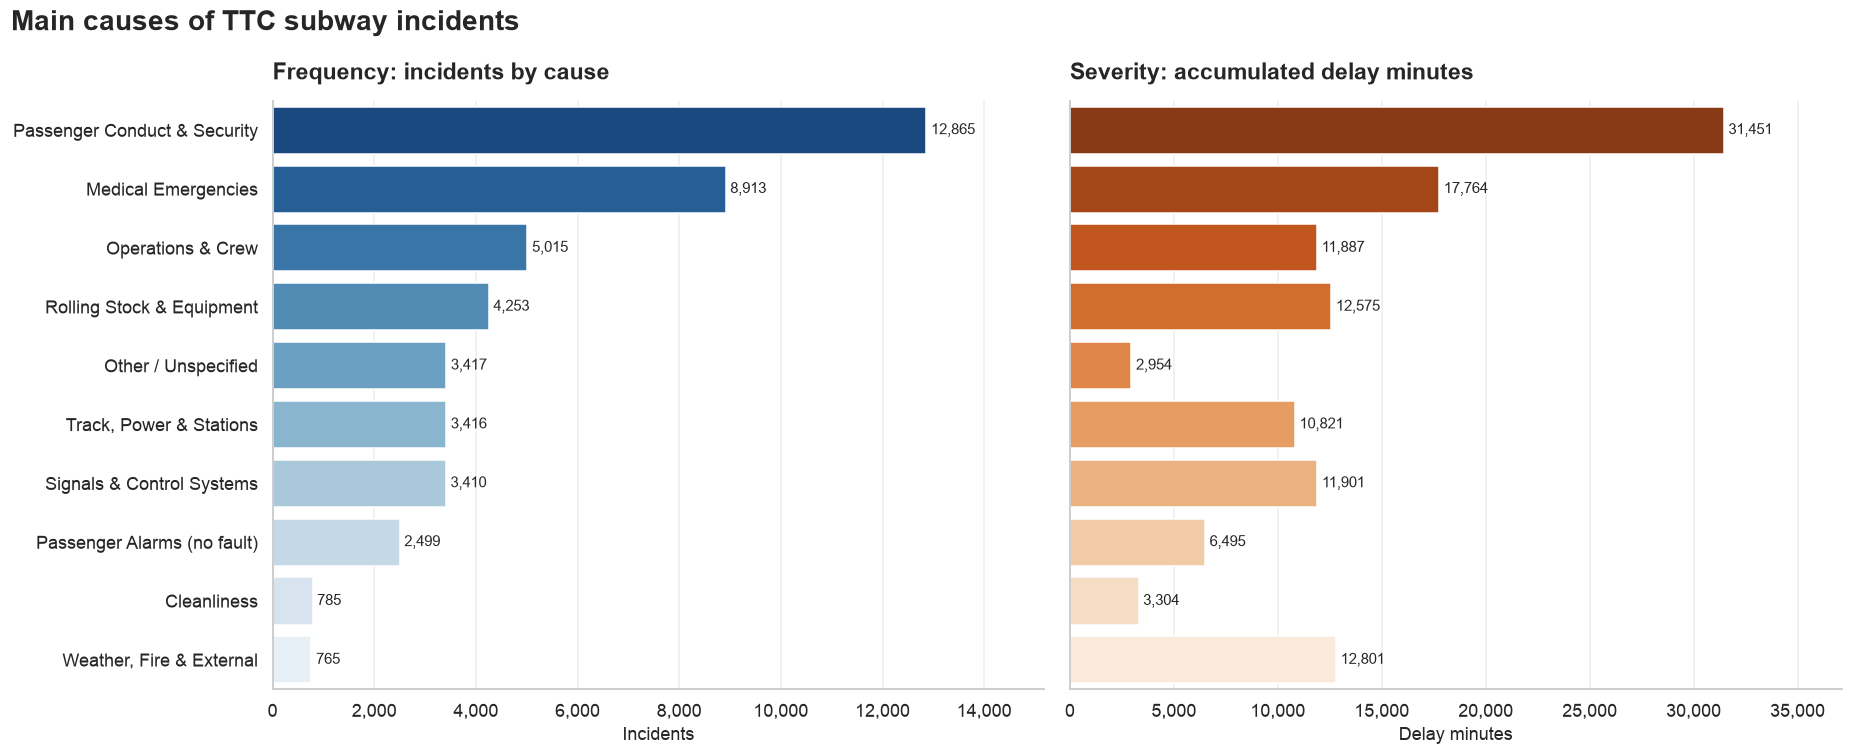

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
order = category_summary.index

sns.barplot(x=category_summary["Incidents"], y=order, hue=order, palette="Blues_r", legend=False, ax=axes[0])
label_bars(axes[0])
format_thousands(axes[0])
style_axis(axes[0], "Frequency: incidents by cause", "Incidents")

minutes = category_summary["Delay_Minutes"]
sns.barplot(x=minutes, y=order, hue=order, palette="Oranges_r", legend=False, ax=axes[1])
label_bars(axes[1])
format_thousands(axes[1])
style_axis(axes[1], "Severity: accumulated delay minutes", "Delay minutes")

for ax in axes:
    ax.margins(x=0.18)
fig.suptitle("Main causes of TTC subway incidents", fontsize=18, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

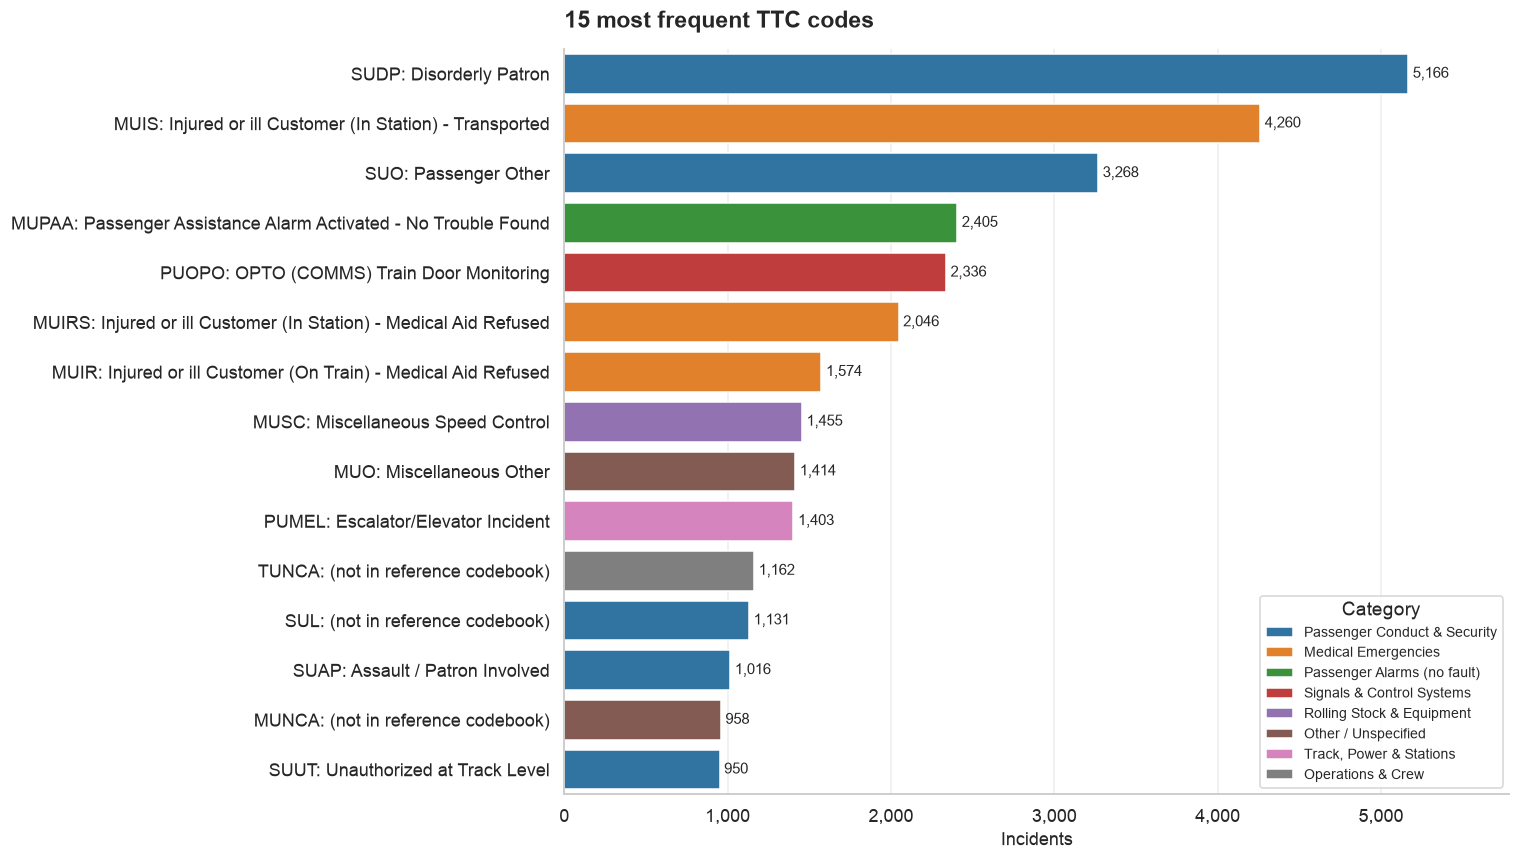

In [43]:
fig, ax = plt.subplots(figsize=(14, 8))
labels = [f"{code}: {desc if len(desc) <= 58 else desc[:57] + '…'}" for code, desc, _ in top_codes.index]
sns.barplot(x=top_codes["Incidents"].values, y=labels, hue=top_codes.index.get_level_values("Incident_Category"),
            dodge=False, palette="tab10", ax=ax)
label_bars(ax)
format_thousands(ax)
ax.margins(x=0.12)
ax.legend(title="Category", loc="lower right", fontsize=9)
style_axis(ax, "15 most frequent TTC codes", "Incidents")
plt.tight_layout()
plt.show()

> Frequency and severity rank causes differently. Passenger conduct leads both panels, while weather is near the bottom by count and **3rd by minutes**. Medical emergencies move the other way: very common, moderate minutes. The top three codes (`SUDP`, `MUIS`, `SUO`) are all passenger-related. The first technical code in the ranking is `PUOPO` (one-person train operation door monitoring).


### 5.2 Time patterns


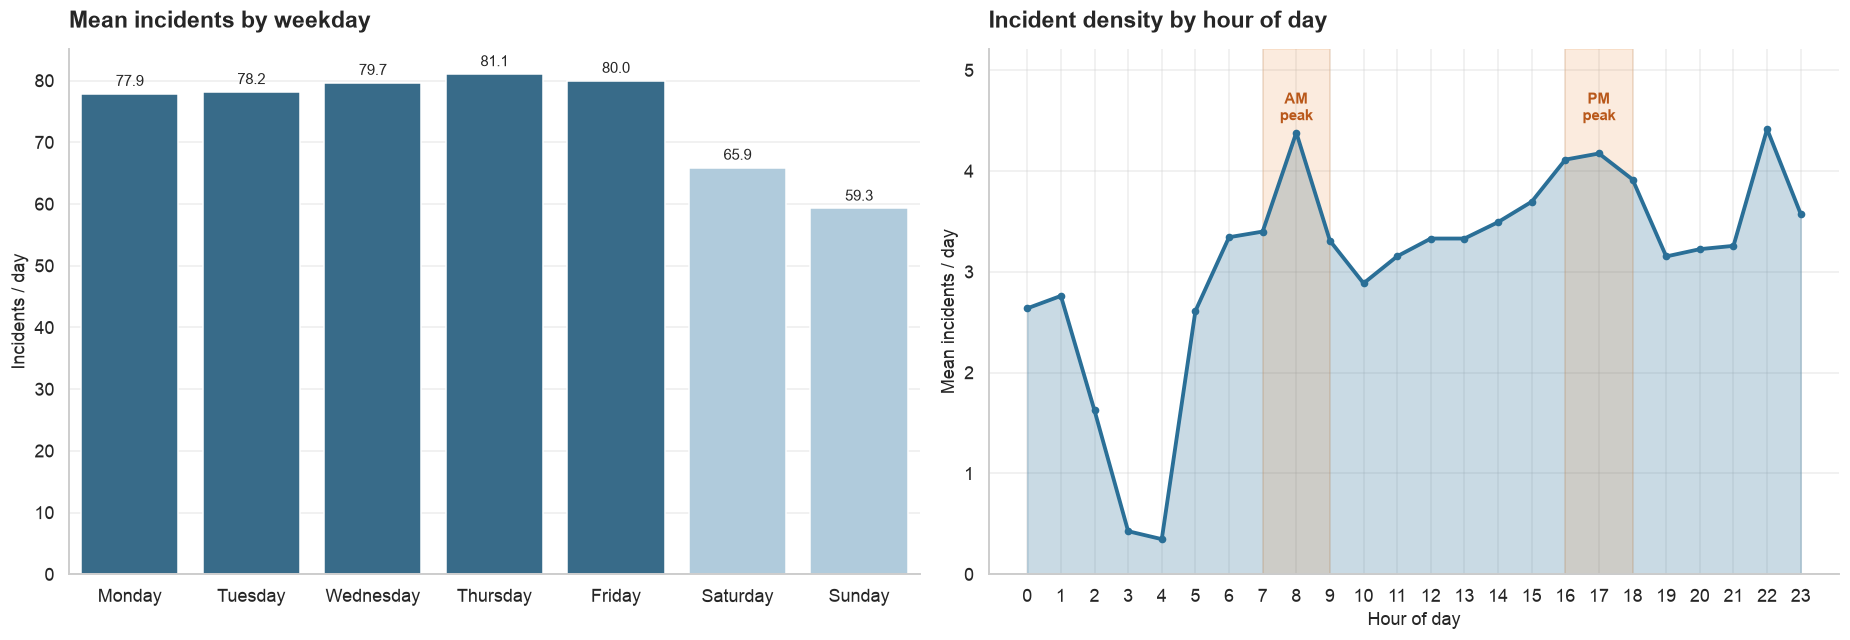

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

day_labels = weekday_summary.index.astype(str).tolist()
day_colors = ["#2A6F97"] * 5 + ["#A9CCE3"] * 2
sns.barplot(x=day_labels, y=weekday_summary["Incidents_per_Day"].values, hue=day_labels,
            palette=day_colors, legend=False, dodge=False, ax=axes[0])
label_bars(axes[0], fmt="{:.1f}")
style_axis(axes[0], "Mean incidents by weekday", "", "Incidents / day")

hourly = hourly_summary["Incidents"] / df["Date"].nunique()
axes[1].fill_between(hourly.index, hourly.values, color="#2A6F97", alpha=0.25)
axes[1].plot(hourly.index, hourly.values, color="#2A6F97", lw=2.5, marker="o", markersize=4)
for start, end in RUSH_HOUR_WINDOWS:
    axes[1].axvspan(start.hour, end.hour, color="#E67E22", alpha=0.15)
axes[1].text(8, hourly.max() * 1.02, "AM\npeak", ha="center", color="#B9581A", fontsize=10, fontweight="bold")
axes[1].text(17, hourly.max() * 1.02, "PM\npeak", ha="center", color="#B9581A", fontsize=10, fontweight="bold")
axes[1].set_xticks(range(24))
axes[1].set_ylim(0, hourly.max() * 1.18)
style_axis(axes[1], "Incident density by hour of day", "Hour of day", "Mean incidents / day")

plt.tight_layout()
plt.show()

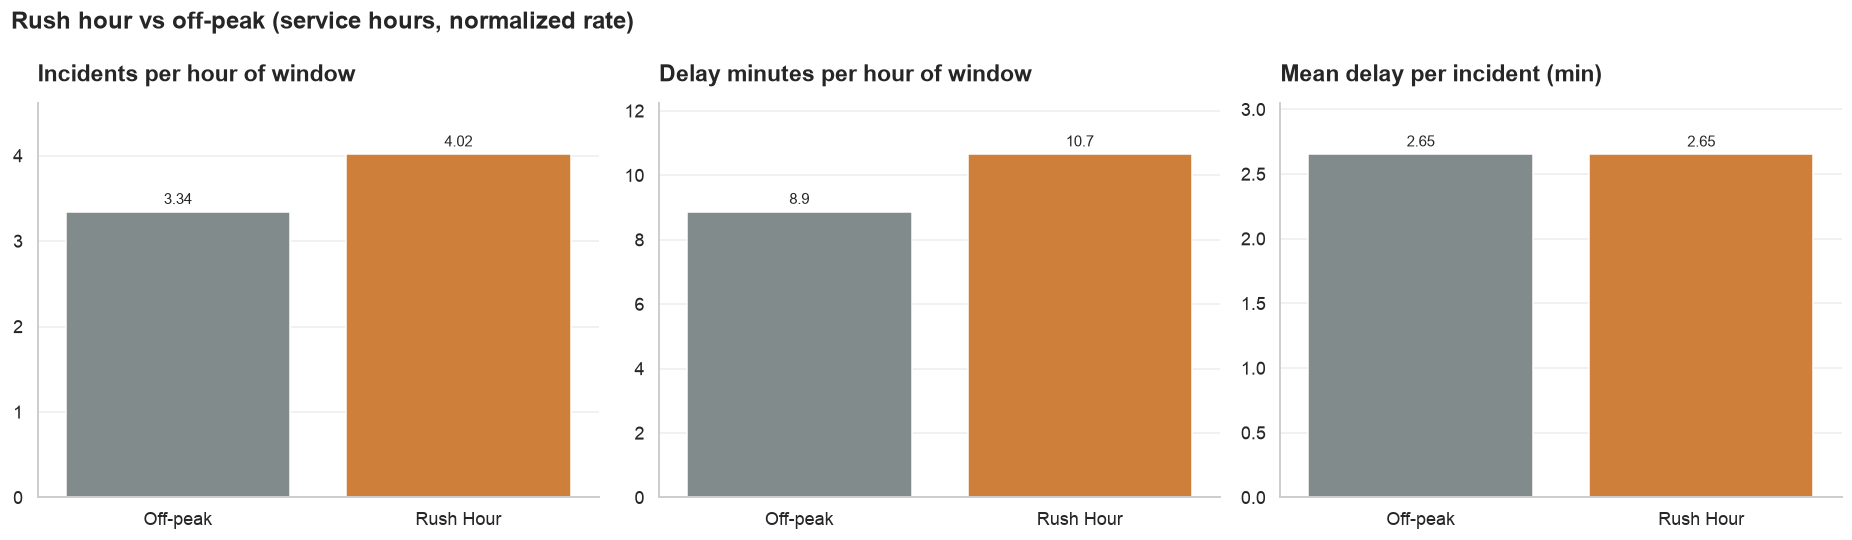

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
rush_colors = {"Rush Hour": "#E67E22", "Off-peak": "#7F8C8D"}
metrics = [
    ("Incidents_per_Hour", "Incidents per hour of window", "{:.2f}"),
    ("Minutes_per_Hour", "Delay minutes per hour of window", "{:.1f}"),
    ("Mean_Delay", "Mean delay per incident (min)", "{:.2f}"),
]
for ax, (column, title, fmt) in zip(axes, metrics):
    sns.barplot(x=rush_summary.index, y=rush_summary[column], hue=rush_summary.index, palette=rush_colors,
                legend=False, ax=ax)
    label_bars(ax, fmt=fmt)
    ax.margins(y=0.15)
    style_axis(ax, title)
fig.suptitle("Rush hour vs off-peak (service hours, normalized rate)", fontsize=16, fontweight="bold",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

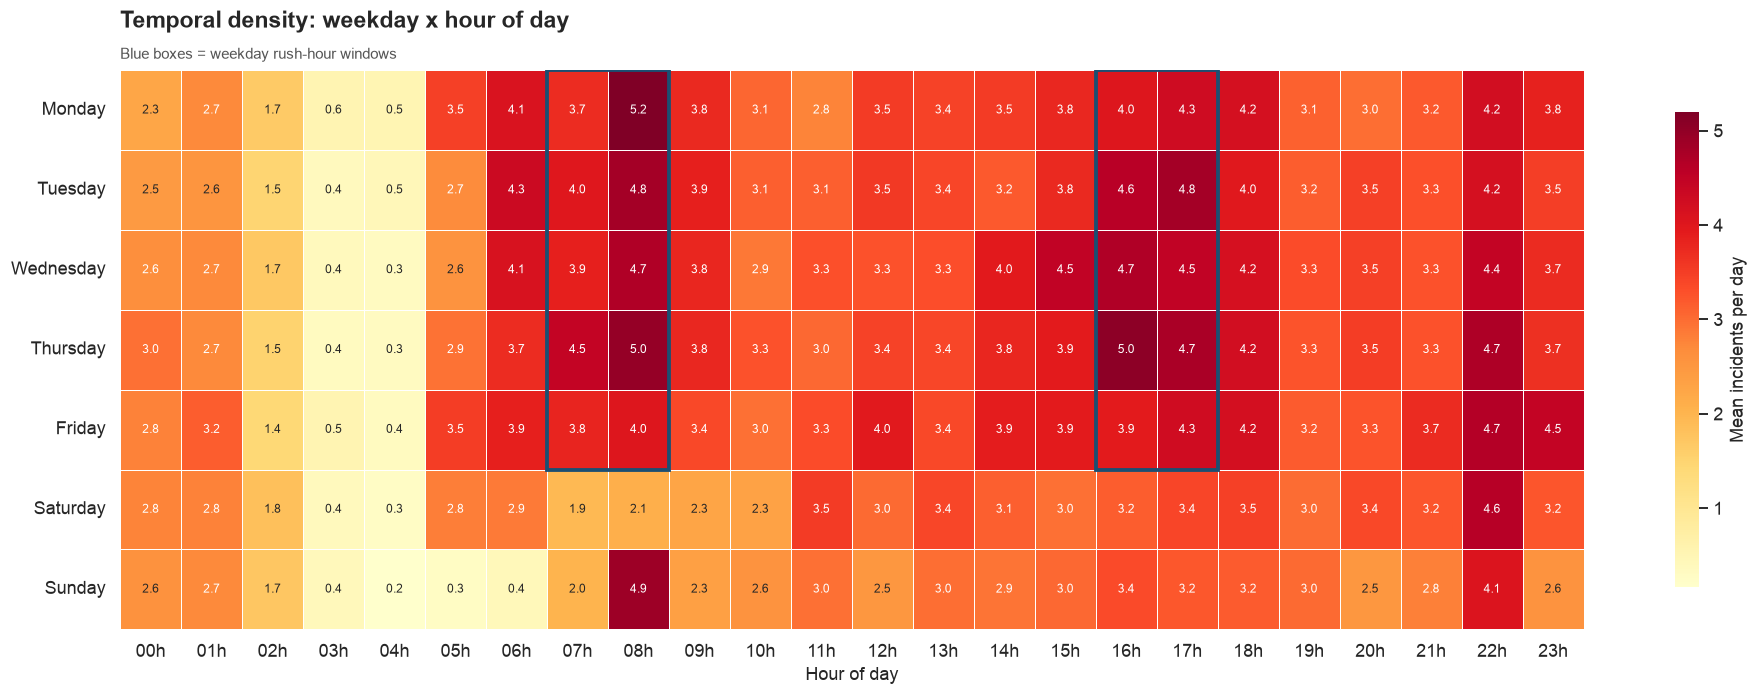

In [46]:
fig, ax = plt.subplots(figsize=(18, 6.5))
sns.heatmap(weekday_hour_matrix, cmap="YlOrRd", linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Mean incidents per day", "shrink": 0.85}, annot=True, fmt=".1f",
            annot_kws={"fontsize": 8}, ax=ax)
for start, end in RUSH_HOUR_WINDOWS:
    ax.add_patch(plt.Rectangle((start.hour, 0), end.hour - start.hour, 5, fill=False, edgecolor="#1B4F72", lw=2.5))
ax.set_xticklabels([f"{h:02d}h" for h in range(24)], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
style_axis(ax, "Temporal density: weekday x hour of day", "Hour of day", "",
           subtitle="Blue boxes = weekday rush-hour windows")
plt.tight_layout()
plt.show()

> Weekdays sit in a tight band (~78-81 incidents per day); Saturday and Sunday drop off. The hourly curve is near zero at 03:00-04:00, jumps at opening (05:00-06:00), and marks both rush windows. Rush hour adds about 20% to the hourly incident rate and to hourly delay minutes, with the same mean delay per incident. On the heatmap the hottest weekday cells are inside the blue rush-hour boxes, led by **Monday at 08:00**, plus the 22:00 band every day. Sunday morning stays quiet until 08:00.

> Response staffing (security, first aid, maintenance on standby) follows that map: weekday peaks and the opening window.


### 5.3 Accumulated delay by line


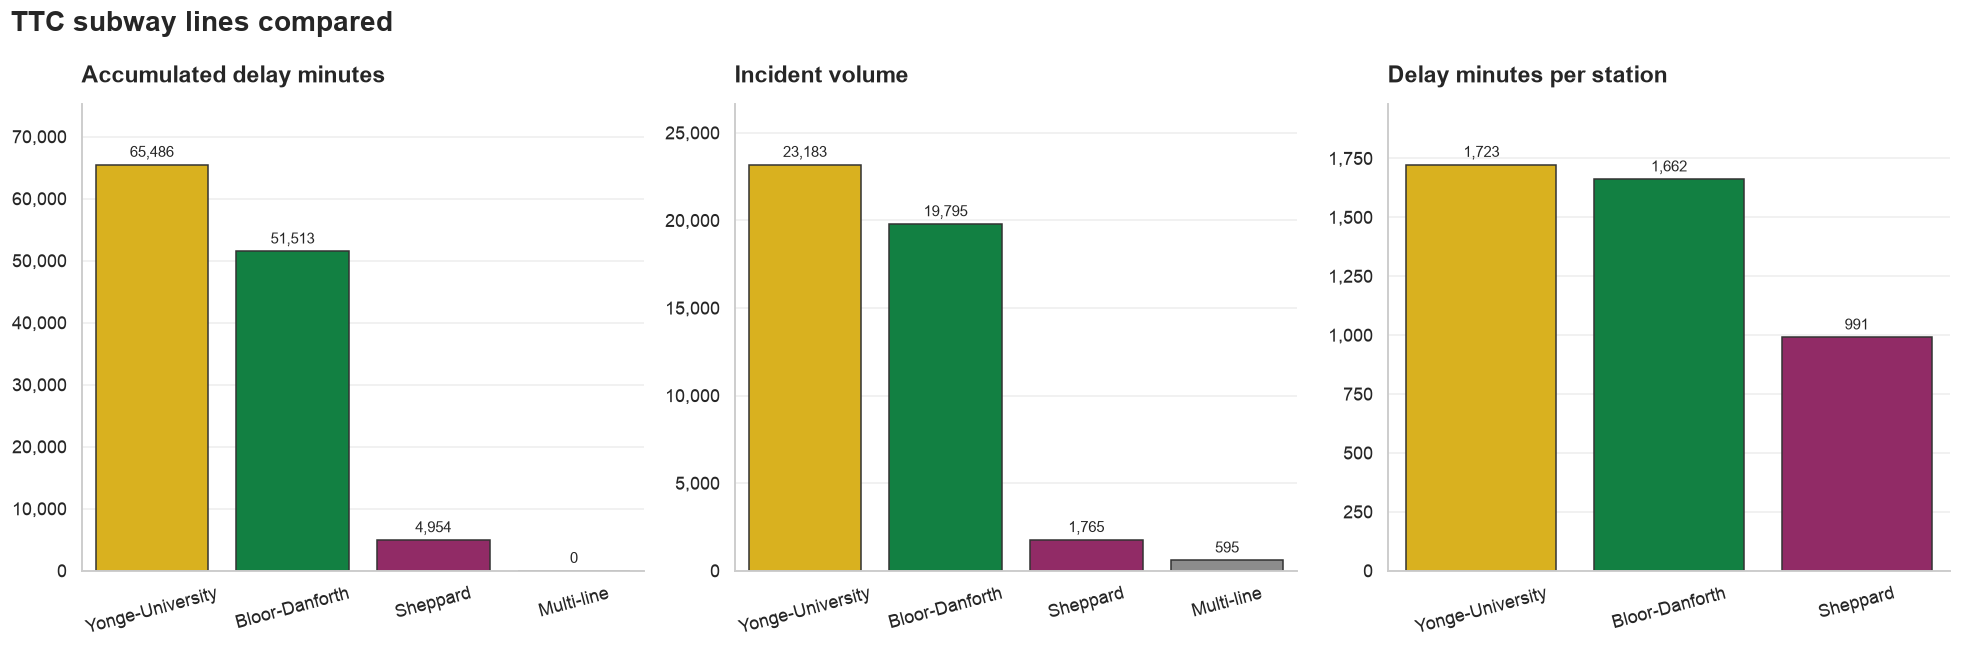

In [47]:
lines_order = line_summary.index
colors = [LINE_COLORS[name] for name in lines_order]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
panels = [
    ("Delay_Minutes", "Accumulated delay minutes", "{:,.0f}"),
    ("Incidents", "Incident volume", "{:,.0f}"),
    ("Minutes_per_Station", "Delay minutes per station", "{:,.0f}"),
]
for ax, (column, title, fmt) in zip(axes, panels):
    data = line_summary[column].dropna()
    sns.barplot(x=data.index, y=data.values, hue=data.index, palette=[LINE_COLORS[n] for n in data.index],
                legend=False, edgecolor="#333333", ax=ax)
    label_bars(ax, fmt=fmt)
    format_thousands(ax, "y")
    ax.margins(y=0.15)
    ax.tick_params(axis="x", rotation=15)
    style_axis(ax, title)
fig.suptitle("TTC subway lines compared", fontsize=18, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

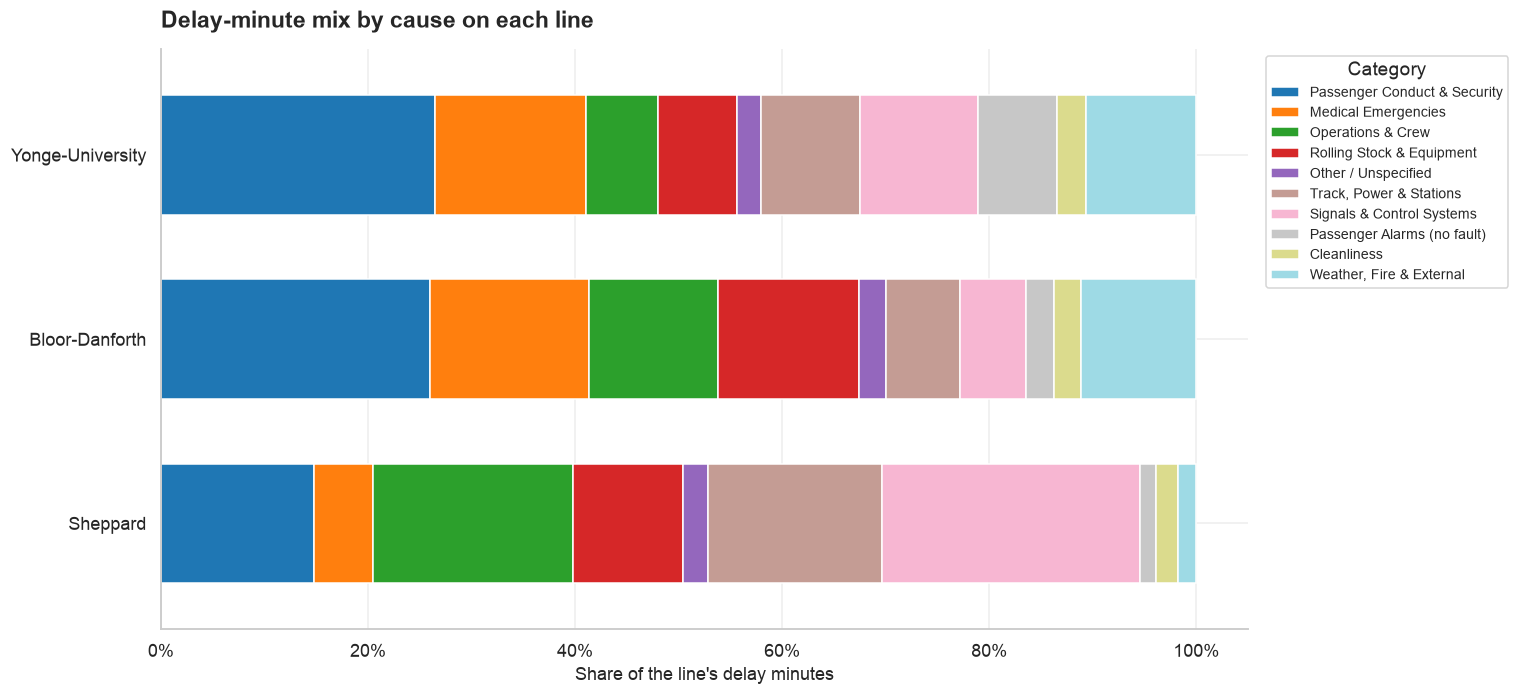

In [48]:
fig, ax = plt.subplots(figsize=(14, 6.5))
share_plot = line_category_share.T.loc[["Yonge-University", "Bloor-Danforth", "Sheppard"]]
share_plot = share_plot[category_summary.index.intersection(share_plot.columns)]
share_plot.plot(kind="barh", stacked=True, colormap="tab20", width=0.65, ax=ax, edgecolor="white")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
ax.invert_yaxis()
style_axis(ax, "Delay-minute mix by cause on each line", "Share of the line's delay minutes")
plt.tight_layout()
plt.show()

> Yonge-University leads in raw minutes. Per station, YU and BD are level. The composition chart splits the response: YU and BD are dominated by passenger conduct, Sheppard by signals and operations.


### 5.4 Ten most affected stations


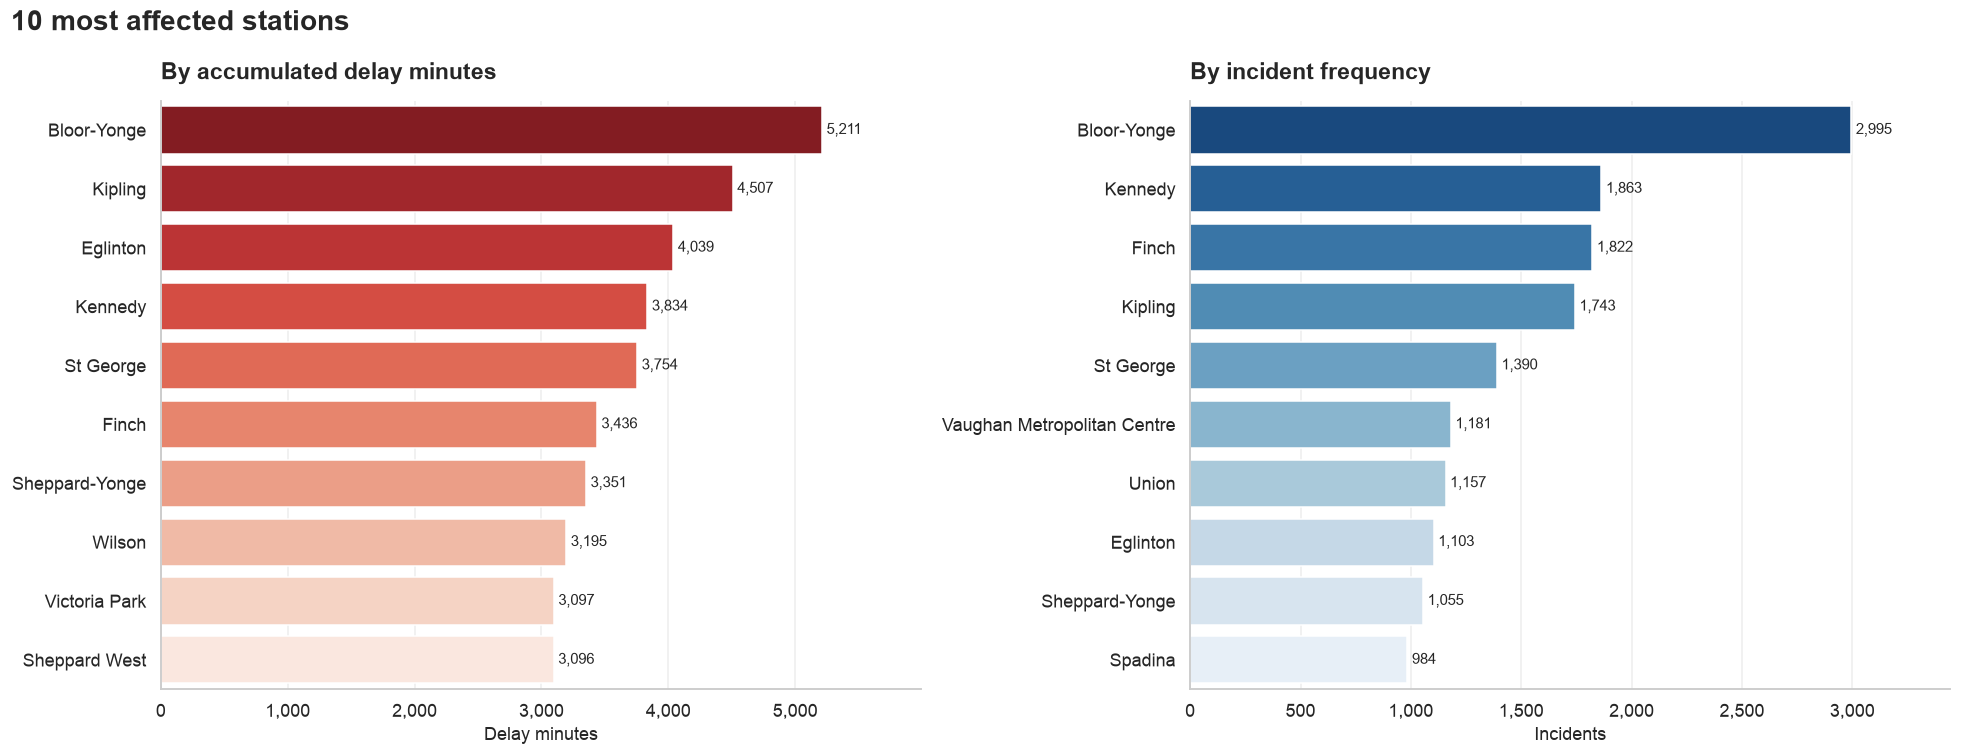

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

def title_case(names):
    return [name.title().replace("'S", "'s").replace("Tmu", "TMU") for name in names]

sns.barplot(x=top10_by_minutes["Delay_Minutes"], y=title_case(top10_by_minutes.index),
            hue=title_case(top10_by_minutes.index), palette="Reds_r", legend=False, ax=axes[0])
label_bars(axes[0])
format_thousands(axes[0])
axes[0].margins(x=0.15)
style_axis(axes[0], "By accumulated delay minutes", "Delay minutes")

sns.barplot(x=top10_by_frequency["Incidents"], y=title_case(top10_by_frequency.index),
            hue=title_case(top10_by_frequency.index), palette="Blues_r", legend=False, ax=axes[1])
label_bars(axes[1])
format_thousands(axes[1])
axes[1].margins(x=0.15)
style_axis(axes[1], "By incident frequency", "Incidents")

fig.suptitle("10 most affected stations", fontsize=18, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

> Bloor-Yonge is alone at the top of both rankings. The two panels split the rest into high-volume, short-delay stations (Finch, Vaughan MC, Union: passenger conduct and medical calls) and moderate-volume, long-delay stations (Eglinton, Sheppard West, Victoria Park, Wilson), which are the better target for a technical investigation. Bloor-Yonge, Kipling, Kennedy, Finch and St George are on both lists.


### 5.5 Passenger impact by cause


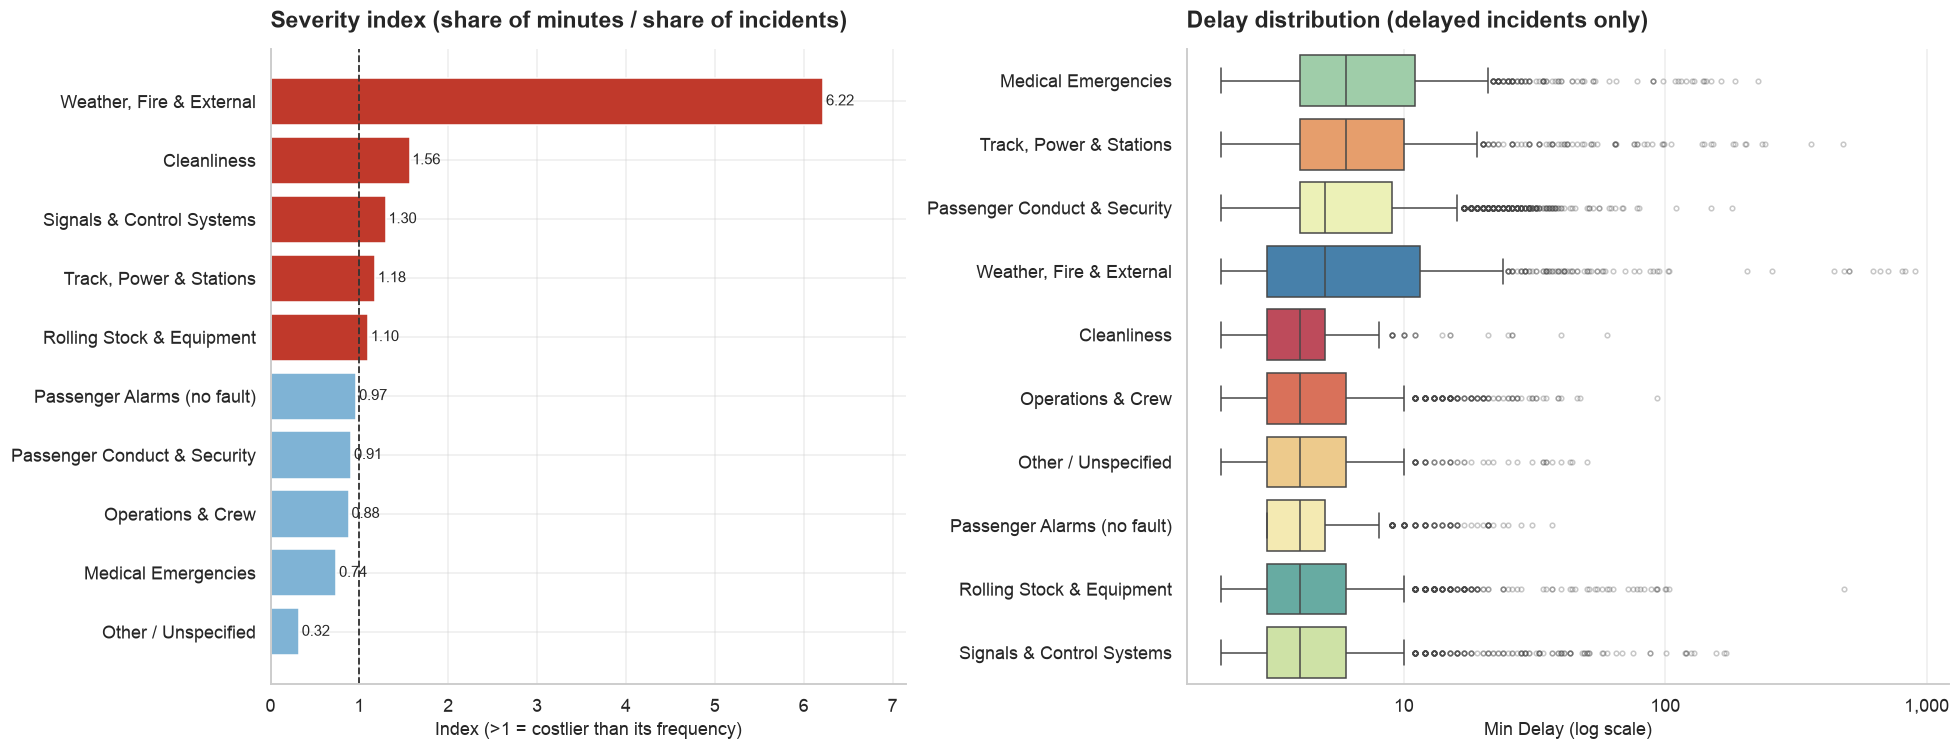

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.2]})

severity = category_impact.sort_values("Severity_Index")
bar_colors = ["#C0392B" if v > 1 else "#7FB3D5" for v in severity["Severity_Index"]]
axes[0].barh(severity.index, severity["Severity_Index"], color=bar_colors)
axes[0].axvline(1, color="#333333", ls="--", lw=1.2)
for y, value in enumerate(severity["Severity_Index"]):
    axes[0].text(value + 0.03, y, f"{value:.2f}", va="center", fontsize=10)
axes[0].margins(x=0.15)
style_axis(axes[0], "Severity index (share of minutes / share of incidents)", "Index (>1 = costlier than its frequency)")

delayed = df[df["Has_Delay"]]
order_box = delayed.groupby("Incident_Category")["Min Delay"].median().sort_values(ascending=False).index
sns.boxplot(data=delayed, y="Incident_Category", x="Min Delay", order=order_box, hue="Incident_Category",
            palette="Spectral", legend=False, ax=axes[1], flierprops={"marker": ".", "alpha": 0.3})
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
style_axis(axes[1], "Delay distribution (delayed incidents only)", "Min Delay (log scale)", "")

plt.tight_layout()
plt.show()

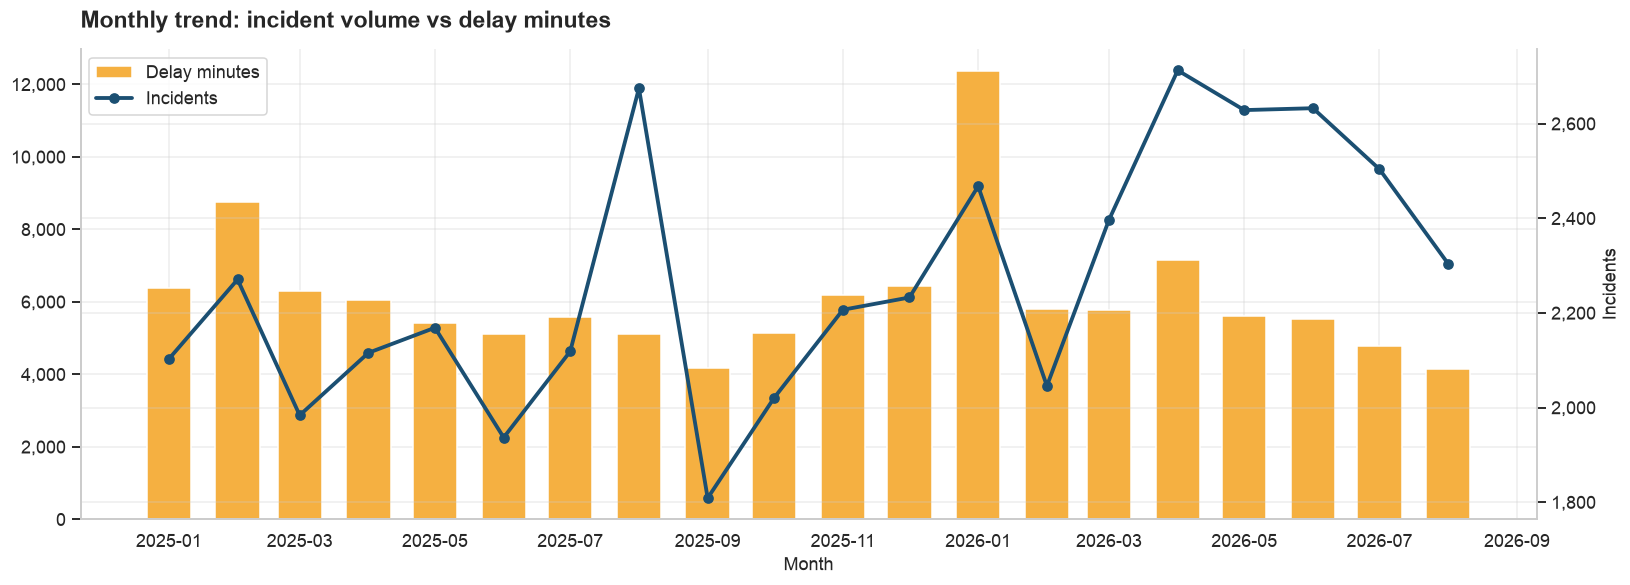

In [51]:
fig, ax = plt.subplots(figsize=(15, 5.5))
monthly = df.groupby("Year_Month").agg(Incidents=("Code", "size"), Minutes=("Min Delay", "sum"))
monthly.index = monthly.index.to_timestamp()

ax.bar(monthly.index, monthly["Minutes"], width=20, color="#F5B041", label="Delay minutes")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["Incidents"], color="#1B4F72", marker="o", lw=2.5, label="Incidents")
ax2.spines["right"].set_visible(True)
format_thousands(ax, "y")
format_thousands(ax2, "y")
ax.set_ylabel("Delay minutes")
ax2.set_ylabel("Incidents")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, ["Delay minutes", "Incidents"], loc="upper left")
style_axis(ax, "Monthly trend: incident volume vs delay minutes", "Month")
plt.tight_layout()
plt.show()

> Red bars (index above 1) are the expensive causes. Weather sits far ahead of cleanliness and the technical groups. Among incidents that do delay service, the median is 4 to 6 minutes in every category. The gap in total minutes comes from the tail: weather and track reach into the hundreds of minutes. Monthly incident counts stay in a band of roughly 1.8k to 2.7k (about 2.1k in 2025, 2.5k in 2026). Delay minutes spike in **February 2025** and especially **January 2026** (~12k minutes, double a typical month), both winter storms.

> A winter contingency plan (rail de-icing, storm trains, extra track crews) has the highest return per event avoided.


---
## 6. Conclusions


In [52]:
key_numbers = {
    "Period": f"{df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d}",
    "Incidents analyzed": f"{len(df):,}",
    "Total delay minutes": f"{df['Min Delay'].sum():,.0f}",
    "Pct of incidents that delay service": pct(df["Has_Delay"].mean()),
    "Most frequent cause": f"{category_summary.index[0]} ({pct(category_summary['Pct_Incidents'].iloc[0])})",
    "Cause with the most minutes": f"{category_impact.index[0]} ({pct(category_impact['Pct_Minutes'].iloc[0])})",
    "Line with the most minutes": f"{line_summary.index[0]} ({line_summary['Delay_Minutes'].iloc[0]:,.0f} min)",
    "Most frequent station": f"{top10_by_frequency.index[0].title()} ({top10_by_frequency['Incidents'].iloc[0]:,})",
    "Station with the most minutes": f"{top10_by_minutes.index[0].title()} ({top10_by_minutes['Delay_Minutes'].iloc[0]:,.0f} min)",
    "Mean Min Delay per incident": f"{df['Min Delay'].mean():.2f} min",
    "Mean Min Gap per incident": f"{df['Min Gap'].mean():.2f} min",
    "Rush-hour lift in incident rate": f"{rush_lift:+.1%}",
}
pd.Series(key_numbers, name="Value").to_frame()

,Value
Period,2025-01-01 to 2026-08-31
Incidents analyzed,"45,338"
Total delay minutes,"121,953"
Pct of incidents that delay service,34.8%
Most frequent cause,Passenger Conduct & Security (28.4%)
Cause with the most minutes,Passenger Conduct & Security (25.8%)
Line with the most minutes,"Yonge-University (65,486 min)"
Most frequent station,"Bloor-Yonge (2,995)"
Station with the most minutes,"Bloor-Yonge (5,211 min)"
Mean Min Delay per incident,2.69 min


### Answers

**1. Volume and causes.** Passenger Conduct & Security is the main cause (~28% of incidents), then Medical Emergencies (~20%) and Operations & Crew (~11%). Technical causes together are ~25%. The most common single code is `SUDP` (disorderly patron).

**2. Time.** Weekdays have ~27% more incidents per day than weekends, with Thursday highest. Rush hour raises the hourly incident rate by 20% (26% on weekdays) and leaves mean delay per incident unchanged. The busiest cell is Monday at 08:00. A second band at 22:00 is mostly administrative logging.

**3. Lines and stations.** Yonge-University has the most minutes (~65k) and incidents (~23k). Per station it matches Bloor-Danforth. Bloor-Yonge is the most critical station on both metrics. The top 10 is terminals (Kipling, Kennedy, Finch, Vaughan MC) and interchanges (St George, Sheppard-Yonge, Spadina).

**4. Passenger impact.** Mean delay per logged incident is ~2.7 min and mean gap is ~3.7 min. Only ~35% of incidents delay service; those average ~7.7 min of delay and ~10.7 min of gap. Passenger conduct leads accumulated minutes (~31k). Weather, Fire & External is the most severe per incident (1.7% of incidents, 10.5% of minutes).

### Recommendations

1. Platform security and passenger assistance at Bloor-Yonge, St George, Union and Eglinton during weekday peaks.
2. Medical coverage at the terminals where medical calls lead: Finch, Kennedy, Vaughan MC.
3. An opening checklist: OPTO door monitoring, clearing work zones, crew on position.
4. A winter plan. Avoiding one storm-scale event saves more minutes than any other single category.
5. A technical focus on Sheppard (signals and crew), whose mix does not match the other lines.

### Limitations

- `Station` and `Line` are free text. About 5% of rows (stretches, yards, a whole line) have no station and are excluded from the station ranking.
- About 25% of rows take a prefix fallback, including recent codes missing from the reference codebook (`TUNCA`, `SUL`, `MUNCA`, `MUINF`).
- `Min Delay` is delay to the **service**, not passengers affected. One minute at Bloor-Yonge at 08:00 hits far more people than one minute on Sheppard at 23:00. Ridership by station and hour is the natural next join.
- The analysis is descriptive. A next mining step is to model whether an incident delays service (classification) or how long it lasts (regression), using the features from step 3.
